# Exploración de activaciones y distritos (caso 1.3): gráficos y mapas

Análisis exploratorio de los datos limpios del caso 1.3, pensado para la presentación intermedia: de aquí salen los números y los gráficos para contar el problema (qué pasa con las emergencias en Madrid), el volumen de datos y las primeras cosas que vemos al cruzar la demanda del SAMUR con el perfil social de los distritos.

Este único notebook reúne todo el análisis gráfico: los 12 gráficos de las secciones 1 a 9 y los 3 mapas de la sección 10. Cada gráfico lleva su explicación: qué se pregunta, qué se ve y qué no se puede concluir. La sección 11 resume los insights para los slides y la 12 recoge las limitaciones.

- **Datos usados:** `activaciones_limpio.csv` (146.567 activaciones del SAMUR en 2024, ya limpio en `data_clean/`, con el tipo y la prioridad del catálogo aplicados), `tabla_distritos.csv` (21 distritos con perfil social, demanda y oferta, en `1_3_clustering/`) y `tipos_emergencia_clean.csv` (catálogo canónico de tipos del caso 2.2, en `data_clean/`; la sección 4 solo añade la categoría, porque el tipo ya viene cruzado de la limpieza). Para los mapas, además, los límites oficiales de los distritos del Ayuntamiento de Madrid (se descargan al ejecutar).
- **Qué hace:** solo explorar y visualizar. No modifica ningún CSV ni rehace la limpieza.
- **Gráficos:** cada uno se guarda como PNG en la subcarpeta `graficos_eda/`, listo para meter en los slides.
- **Ojo al interpretar:** son 21 distritos y las correlaciones entre distritos no prueban causalidad. Los mapas son descriptivos: los terciles del mapa bivariante no son el clustering. Las dudas concretas están apuntadas al final (sección "Limitaciones").

## 0. Carga de datos

Leemos los CSV ya limpios (los que salen de los notebooks de limpieza y de cruces), para que todo lo que se vea aquí sea reproducible desde el repo. Si el notebook está en `data_viz/`, las rutas relativas llegan solas; si no, se prueban otras ubicaciones típicas.

Decisión: para los análisis por hora usamos `hora_solicitud` (cuándo pide ayuda la gente, que es lo que interesa para planificar). Las 1.579 filas sin hora de solicitud se excluyen solo de esos gráficos, no del resto.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
Path('graficos_eda').mkdir(exist_ok=True)

def cargar(nombre, carpetas):
    for c in carpetas:
        ruta = Path(c) / nombre
        if ruta.exists():
            return pd.read_csv(ruta)
    raise FileNotFoundError(nombre)

act = cargar('activaciones_limpio.csv', ['../data_clean', '.'])
tabla = cargar('tabla_distritos.csv', ['../1_3_clustering', '.'])

# Hora de la solicitud (0-23) para los análisis por franja horaria
act['hora'] = pd.to_datetime(act['hora_solicitud'], format='%H:%M:%S', errors='coerce').dt.hour

MESES = ['ENERO','FEBRERO','MARZO','ABRIL','MAYO','JUNIO','JULIO','AGOSTO','SEPTIEMBRE','OCTUBRE','NOVIEMBRE','DICIEMBRE']

ROJO = '#D62612'      # acento SAMUR
GRIS = '#9aa0a6'      # contexto
AZUL = '#1a73e8'      # secundario

plt.rcParams.update({
    'figure.figsize': (10, 5.6), 'figure.dpi': 170,
    'font.size': 13, 'axes.titlesize': 17, 'axes.titleweight': 'bold',
    'axes.labelsize': 13, 'axes.edgecolor': '#cccccc',
    'axes.grid': True, 'grid.color': '#e8e8e8', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'figure.facecolor': 'white',
})

print(f"Activaciones: {len(act):,}".replace(',', '.'))
print(f"Distritos: {len(tabla)}")
print(f"Filas sin hora de solicitud: {act['hora'].isna().sum():,} (se excluyen solo de los análisis por hora)".replace(',', '.'))

Activaciones: 146.567
Distritos: 21
Filas sin hora de solicitud: 1.422 (se excluyen solo de los análisis por hora)


## 1. El volumen: más de 150.000 activaciones en un año

La presentación pide que se entienda el volumen de datos, así que empezamos por ahí. Contamos activaciones por mes para ver si la demanda es estable o tiene temporadas.

Decisión: como 2024 es bisiesto, el dato por día se calcula sobre 366 días.

Total 2024: 146.567 activaciones
Media: 400 al día, unas 17 cada hora
Mes con más actividad diaria: JUNIO (438/día)
Mes con menos: AGOSTO (338/día)
Agosto tiene un 23% menos actividad diaria que junio


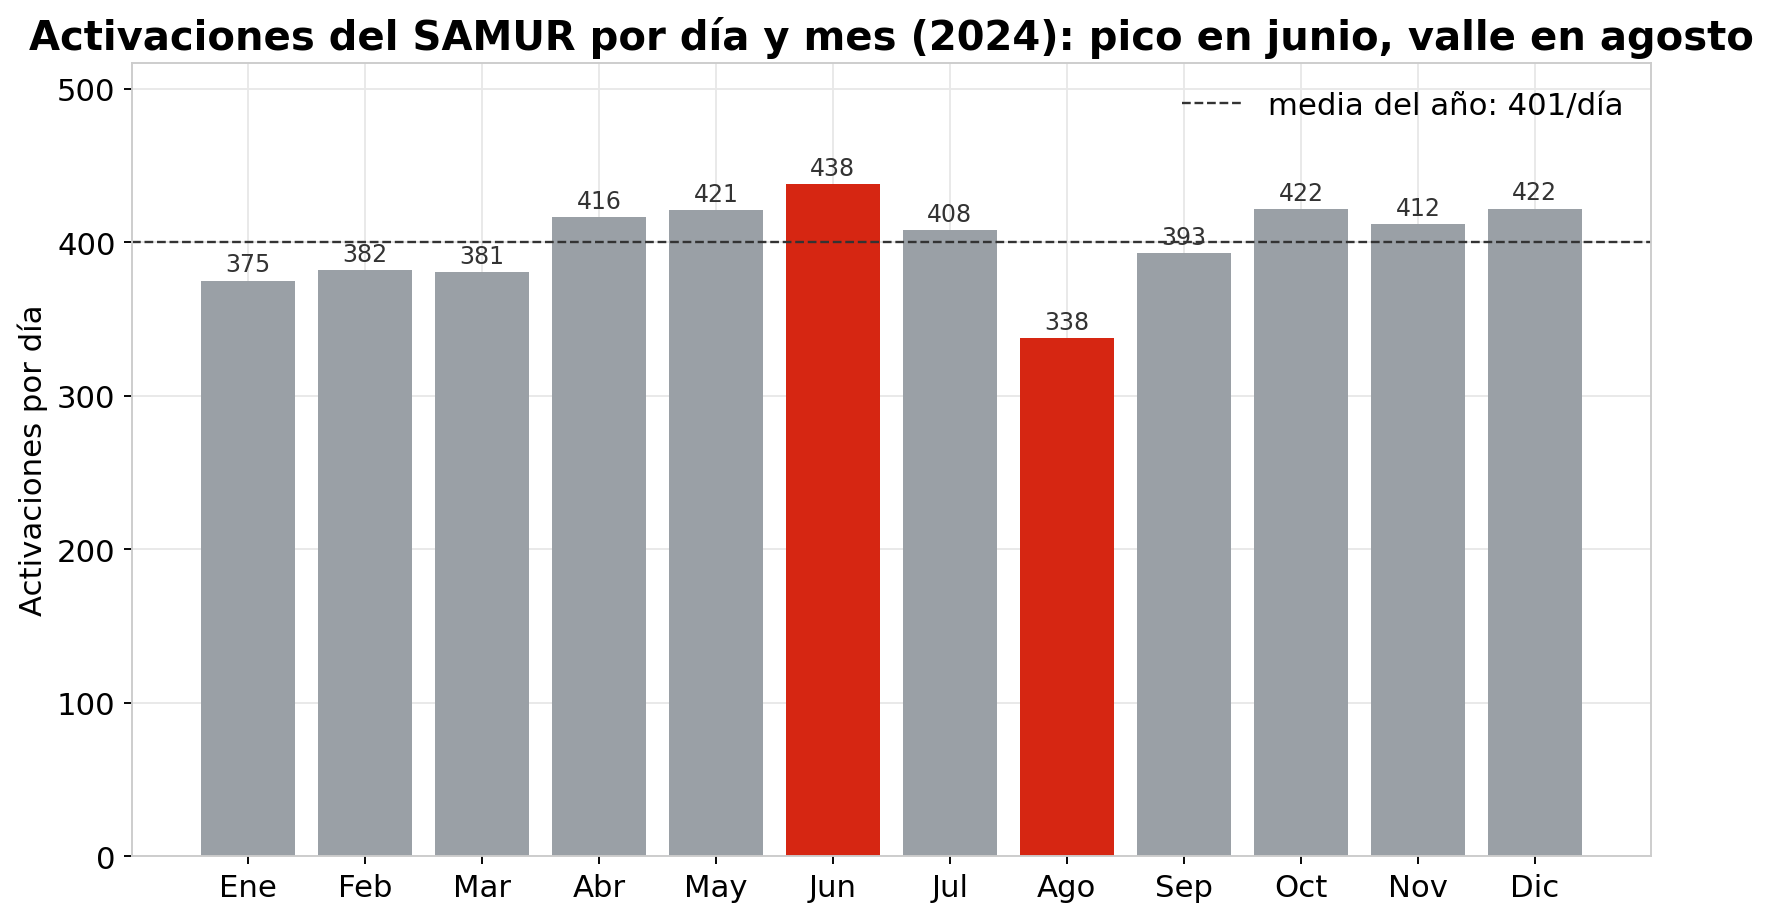

In [2]:
total = len(act)
por_dia = total / 366
print(f"Total 2024: {total:,} activaciones".replace(',', '.'))
print(f"Media: {por_dia:.0f} al día, unas {por_dia/24:.0f} cada hora")

# Los meses no tienen los mismos días, así que comparamos activaciones POR DÍA
dias_mes = pd.Series([31,29,31,30,31,30,31,31,30,31,30,31], index=MESES)  # 2024 bisiesto
por_mes = act['mes'].value_counts().reindex(MESES)
por_dia_mes = por_mes / dias_mes
print(f"Mes con más actividad diaria: {por_dia_mes.idxmax()} ({por_dia_mes.max():.0f}/día)")
print(f"Mes con menos: {por_dia_mes.idxmin()} ({por_dia_mes.min():.0f}/día)")
print(f"Agosto tiene un {(1-por_dia_mes['AGOSTO']/por_dia_mes['JUNIO'])*100:.0f}% menos actividad diaria que junio")

fig, ax = plt.subplots()
colores = [ROJO if m in (por_dia_mes.idxmax(), por_dia_mes.idxmin()) else GRIS for m in MESES]
ax.bar(range(12), por_dia_mes.values, color=colores)
ax.axhline(por_dia_mes.mean(), color='#333333', linestyle='--', linewidth=1, label=f'media del año: {por_dia_mes.mean():.0f}/día')
ax.set_xticks(range(12))
ax.set_xticklabels([m[:3].title() for m in MESES])
ax.set_ylabel('Activaciones por día')
ax.set_title('Activaciones del SAMUR por día y mes (2024): pico en junio, valle en agosto')
ax.legend(frameon=False)
ax.set_ylim(0, por_dia_mes.max() * 1.18)
for i, v in enumerate(por_dia_mes.values):
    ax.text(i, v + 6, f'{v:.0f}', ha='center', fontsize=10, color='#333333')
plt.tight_layout()
plt.savefig('graficos_eda/activaciones_por_mes.png', bbox_inches='tight')
plt.show()

**Lo que vemos:** unas **400 activaciones al día** de media (146.567 entre 366 días). Comparando por día (los meses no tienen los mismos días), junio es el mes con más actividad (438/día) y agosto el de menos (338/día, un 23% menos que junio). La lectura de que en agosto Madrid se vacía es una hipótesis razonable, no algo que el dato pruebe por sí solo. La demanda no es plana, así que tiene sentido estudiar cuándo hacen falta más recursos.

## 2. A qué hora pasan las cosas

Para planificar turnos importa la hora del día. Contamos activaciones por hora de solicitud y cruzamos mes × hora para comprobar si el patrón diario se mantiene todo el año o cambia con la temporada.

Hora punta: 13h (9.904 activaciones)
Hora valle: 4h (2.974 activaciones)
Entre una y otra hay 3.3x más llamadas


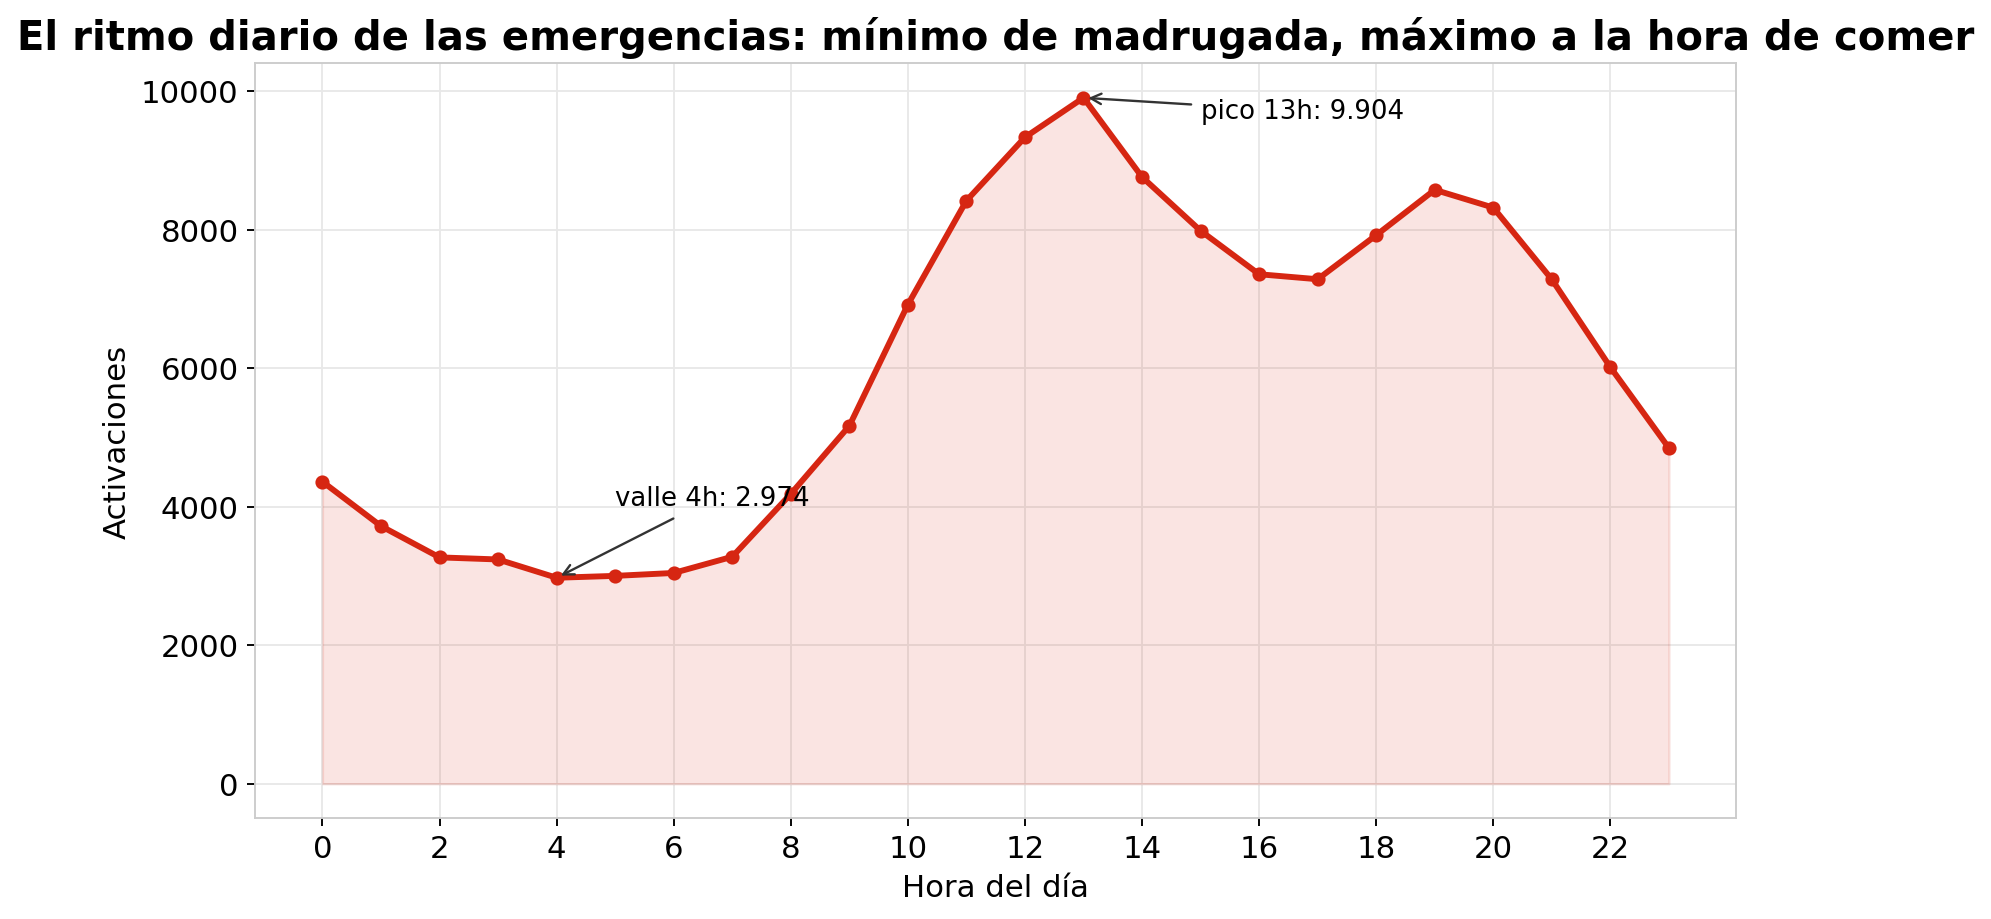

In [3]:
por_hora = act['hora'].value_counts().sort_index()
print(f"Hora punta: {int(por_hora.idxmax())}h ({por_hora.max():,} activaciones)".replace(',', '.'))
print(f"Hora valle: {int(por_hora.idxmin())}h ({por_hora.min():,} activaciones)".replace(',', '.'))
print(f"Entre una y otra hay {por_hora.max()/por_hora.min():.1f}x más llamadas")

fig, ax = plt.subplots()
ax.plot(por_hora.index, por_hora.values, color=ROJO, linewidth=2.5, marker='o', markersize=5)
ax.fill_between(por_hora.index, por_hora.values, alpha=0.12, color=ROJO)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel('Hora del día')
ax.set_ylabel('Activaciones')
ax.set_title('El ritmo diario de las emergencias: mínimo de madrugada, máximo a la hora de comer')
ax.annotate(f'pico {int(por_hora.idxmax())}h: {por_hora.max():,}'.replace(',', '.'),
            xy=(por_hora.idxmax(), por_hora.max()), xytext=(15, por_hora.max()*0.97),
            arrowprops=dict(arrowstyle='->', color='#333333'), fontsize=11)
ax.annotate(f'valle {int(por_hora.idxmin())}h: {por_hora.min():,}'.replace(',', '.'),
            xy=(por_hora.idxmin(), por_hora.min()), xytext=(5, por_hora.min()*1.35),
            arrowprops=dict(arrowstyle='->', color='#333333'), fontsize=11)
plt.tight_layout()
plt.savefig('graficos_eda/activaciones_por_hora.png', bbox_inches='tight')
plt.show()

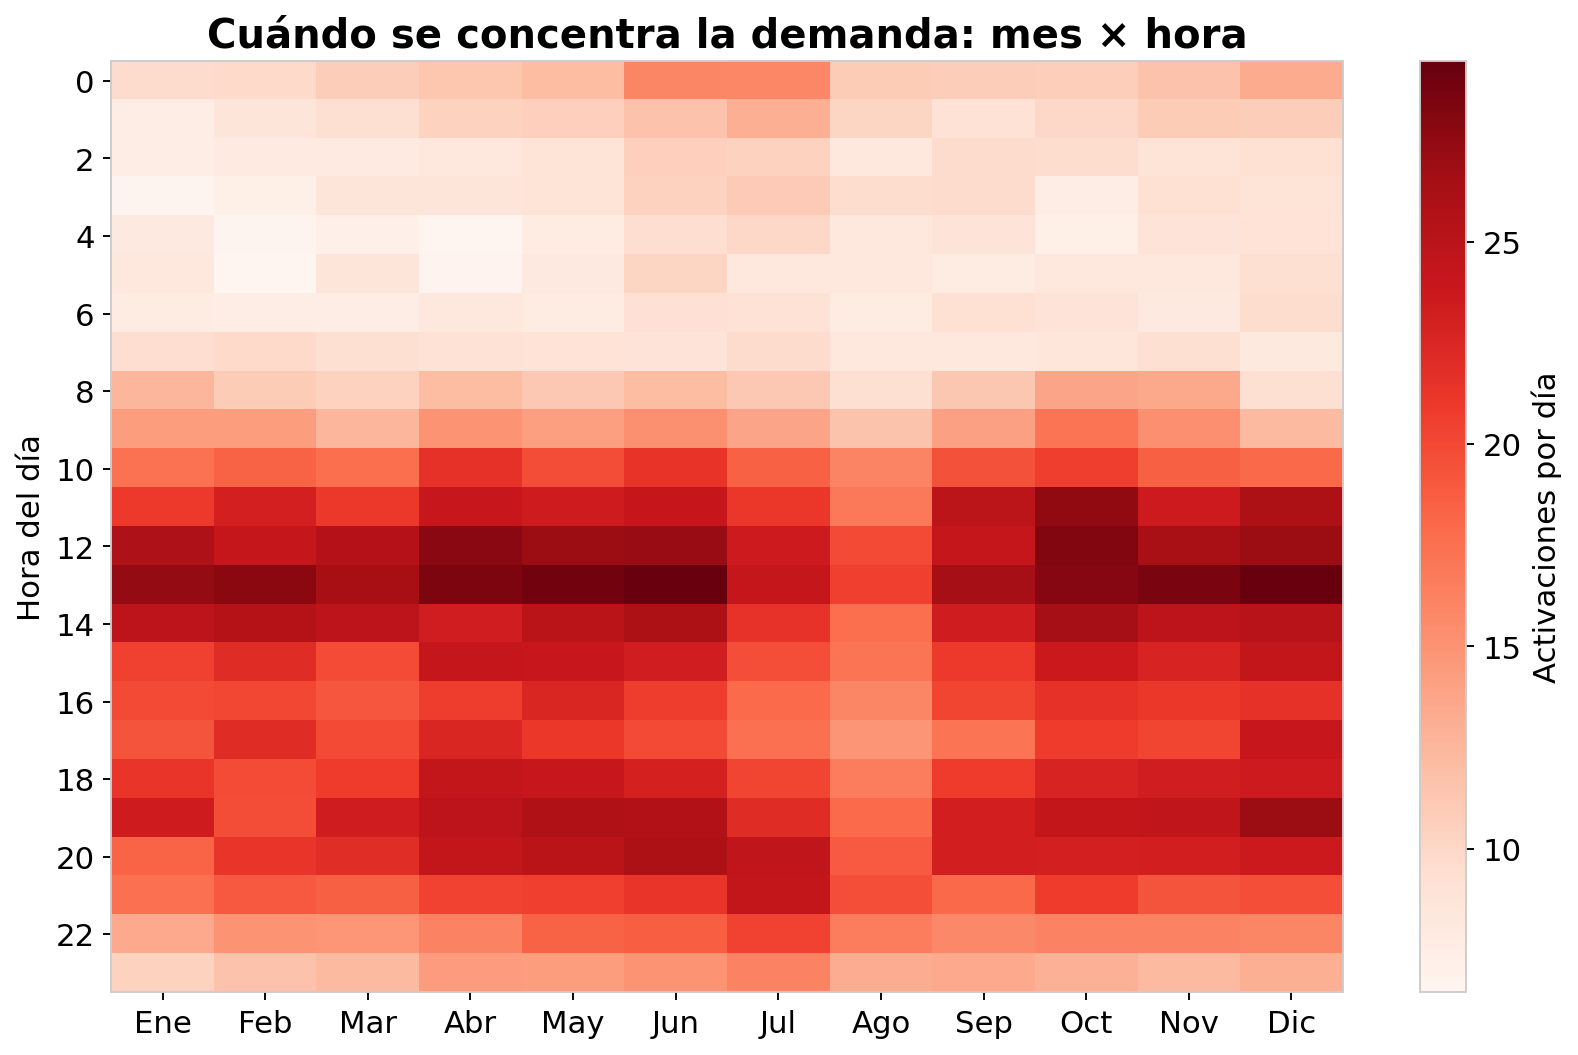

In [4]:
# Mapa de calor mes x hora: en rojo más activaciones
matriz = act.pivot_table(index='hora', columns='mes', values='activacion_id', aggfunc='count').reindex(columns=MESES)
matriz = matriz / dias_mes

fig, ax = plt.subplots(figsize=(10, 6.4))
im = ax.imshow(matriz.values, aspect='auto', cmap='Reds')
ax.set_xticks(range(12))
ax.set_xticklabels([m[:3].title() for m in MESES])
ax.set_yticks(range(0, 24, 2))
ax.set_ylabel('Hora del día')
ax.set_title('Cuándo se concentra la demanda: mes × hora')
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Activaciones por día')
ax.grid(False)
plt.tight_layout()
plt.savefig('graficos_eda/heatmap_mes_hora.png', bbox_inches='tight')
plt.show()

**Lo que vemos:** la demanda baja de madrugada (mínimo sobre las 4-5h) y sube hasta el mediodía, con el pico a las **13h** (casi 10.000 activaciones en el año, 3,3 veces más que a las 4h). El mapa de calor (normalizado por días de cada mes para que sean comparables) muestra un patrón diario parecido en todos los meses: no es cosa de un mes concreto.

## 3. La noche es otra emergencia

De día manda la patología cardiovascular; de madrugada, el ocio. Para verlo, calculamos qué porcentaje de las llamadas de cada hora son por intoxicación etílica.

Decisión: mostramos el porcentaje dentro de cada hora (no el total), porque de madrugada hay menos llamadas en total y el volumen bruto escondería el efecto. Limitación: el dato abierto no trae el día de la semana, así que no podemos separar fin de semana de laborable (Bluetab lo confirmó por correo).

Tipo nº1 de 0 a 7h: Intoxicación etílica
Intoxicación etílica a las 3h: 31% de las llamadas
Intoxicación etílica a las 12h: 3% de las llamadas
En todo el año: 10% de las activaciones


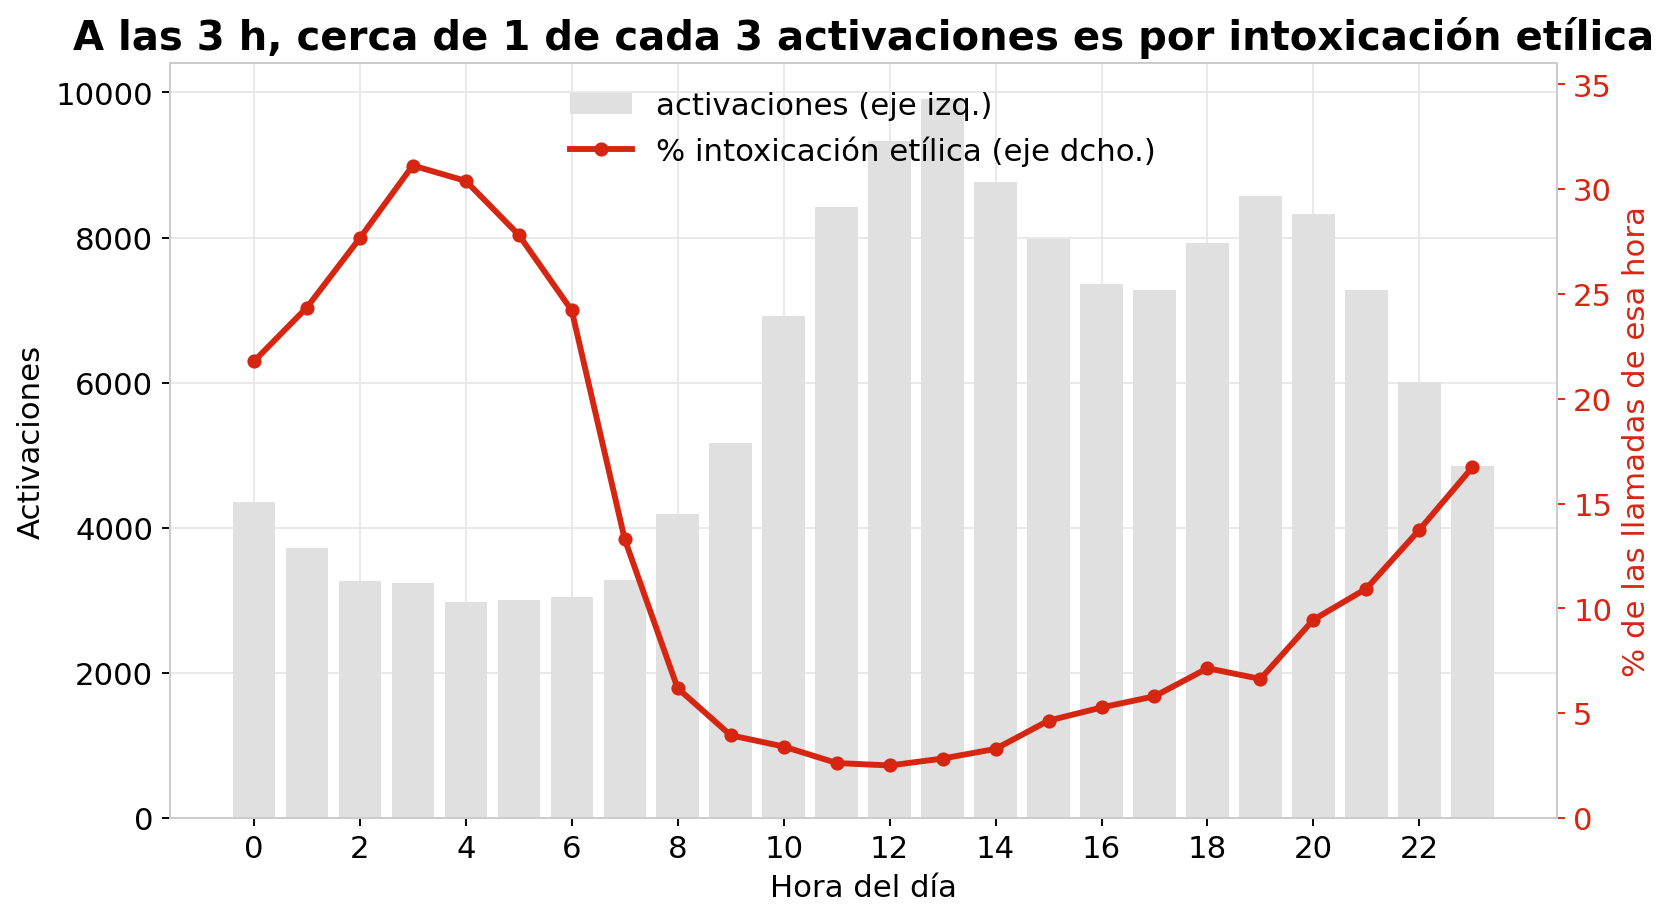

In [5]:
con_hora = act.dropna(subset=['hora'])
es_ie = con_hora['tipo_emergencia'] == 'Intoxicación etílica'  # código exacto del catálogo
share_ie = es_ie.groupby(con_hora['hora']).mean() * 100

# De madrugada (0-7h), ¿cuál es el tipo nº1?
madrugada = con_hora[con_hora['hora'] < 7]
print("Tipo nº1 de 0 a 7h:", madrugada['tipo_emergencia'].value_counts().idxmax())
print(f"Intoxicación etílica a las 3h: {share_ie[3]:.0f}% de las llamadas")
print(f"Intoxicación etílica a las 12h: {share_ie[12]:.0f}% de las llamadas")
tot_ie = es_ie.mean() * 100
print(f"En todo el año: {tot_ie:.0f}% de las activaciones")

fig, ax = plt.subplots()
ax.bar(por_hora.index, por_hora.values, color='#e0e0e0', label='activaciones (eje izq.)')
ax.set_xlabel('Hora del día')
ax.set_ylabel('Activaciones')
ax.set_xticks(range(0, 24, 2))
ax2 = ax.twinx()
ax2.plot(share_ie.index, share_ie.values, color=ROJO, linewidth=2.5, marker='o', markersize=5,
         label='% intoxicación etílica (eje dcho.)')
ax2.set_ylabel('% de las llamadas de esa hora', color=ROJO)
ax2.tick_params(axis='y', colors=ROJO)
ax2.grid(False)
ax2.set_ylim(0, 36)
ax.set_title('A las 3 h, cerca de 1 de cada 3 activaciones es por intoxicación etílica')
lineas = ax.get_legend_handles_labels()
lineas2 = ax2.get_legend_handles_labels()
ax.legend(lineas[0] + lineas2[0], lineas[1] + lineas2[1], frameon=False, loc='upper center')
plt.tight_layout()
plt.savefig('graficos_eda/intoxicacion_nocturna.png', bbox_inches='tight')
plt.show()

**Lo que vemos:** entre las 0 y las 7h la intoxicación etílica es el **tipo de emergencia nº1**, y a las 3 de la mañana es el **31%** de todas las llamadas (a mediodía no llega al 3%). Es el mismo servicio, pero dos realidades distintas según la hora, y eso importa para decidir qué recursos hacen falta en cada turno.

## 4. Categorías del catálogo de tipos (cohesión con el caso 2.2)

Desde la última versión de la limpieza de activaciones, `tipo_emergencia` **ya es** el código del catálogo canónico (`tipos_emergencia_clean.csv`, 39 tipos): la limpieza resolvió los alias y eliminó las filas cuyo tipo no describía una urgencia, así que el 100% de las activaciones tiene tipo catalogado. Aquí solo añadimos la **categoría** de cada tipo con un `merge` directo, para ver el reparto general del servicio.

Nota de cohesión: la prioridad que traen ahora las activaciones es la del catálogo (lo grave que suele ser cada tipo), no la registrada en cada evento; la del registro solo coincidía con ella en el 37,7% de las filas. El detalle está en `limpieza_activaciones.ipynb` (sección "Criterio del catálogo").

In [6]:
cat = cargar('tipos_emergencia_clean.csv', ['../data_clean', '.'])

# Merge directo: tipo_emergencia ya es el codigo del catalogo (lo dejo asi la limpieza)
act = act.merge(cat[['codigo', 'categoria_correcta', 'prioridad_base_correcta']],
                left_on='tipo_emergencia', right_on='codigo', how='left').drop(columns=['codigo'])
act['tipo_figura'] = act['tipo_emergencia']  # etiqueta para figuras: el codigo literal del catalogo

clasificada = act['categoria_correcta'].notna()
print(f"Clasificadas en el catálogo: {clasificada.sum():,} de {len(act):,} ({clasificada.mean()*100:.2f}%)".replace(',', '.'))
assert clasificada.all(), 'La limpieza garantiza que el 100% trae tipo del catálogo'

Clasificadas en el catálogo: 146.567 de 146.567 (100.00%)


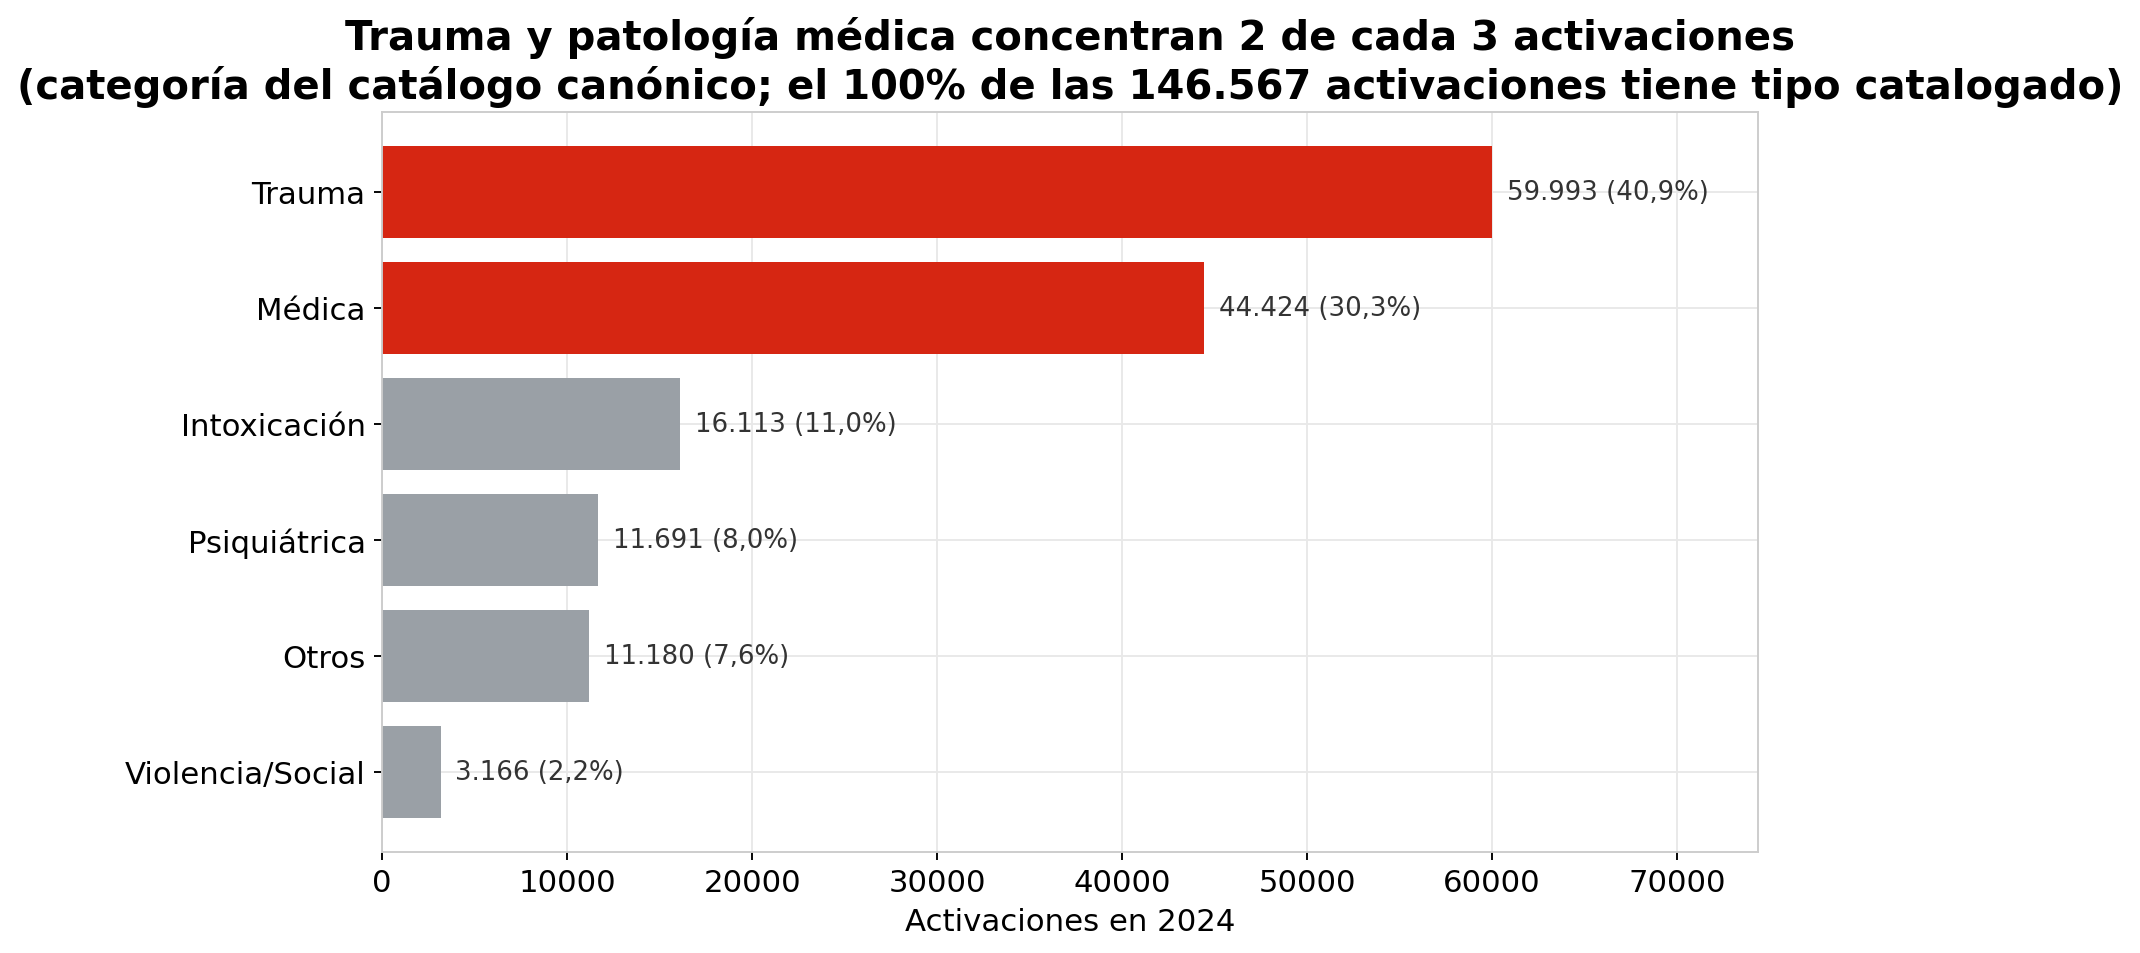

In [7]:
total = len(act)
por_cat = act['categoria_correcta'].value_counts()
etiquetas = list(por_cat.index)
valores = list(por_cat.values)
colores = [ROJO if e in ('Trauma', 'Médica') else GRIS for e in etiquetas]

fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(range(len(etiquetas)), valores[::-1], color=colores[::-1])
ax.set_yticks(range(len(etiquetas)))
ax.set_yticklabels(etiquetas[::-1])
for i, v in enumerate(valores[::-1]):
    etiqueta_valor = f"{v:,}".replace(',', '.') + ' (' + f"{v/total*100:.1f}".replace('.', ',') + '%)'
    ax.text(v + 800, i, etiqueta_valor, va='center', fontsize=11, color='#333333')
ax.set_xlabel('Activaciones en 2024')
ax.set_title('Trauma y patología médica concentran 2 de cada 3 activaciones\n'
             '(categoría del catálogo canónico; el 100% de las 146.567 activaciones tiene tipo catalogado)')
ax.set_xlim(0, max(valores) * 1.24)
plt.tight_layout()
plt.savefig('graficos_eda/activaciones_por_categoria.png', bbox_inches='tight')
plt.show()

**Lo que vemos:** con las categorías del catálogo, **trauma (59.993, 40,9%) y patología médica (44.424, 30,3%) concentran más de 2 de cada 3 activaciones** del año; las intoxicaciones pesan un 11,0%. Esto conecta directo con el clustering: el "para qué" de la demanda de cada distrito se puede perfilar con estas categorías.

Ya no queda nada fuera del catálogo: la limpieza resolvió los alias (597 filas de abreviaturas y 1.564 de equivalencias clínicas, documentadas en `limpieza_activaciones.ipynb`) y eliminó 5.513 filas (el 3,6%) cuyo `tipo_emergencia` no describía una urgencia (recursos enviados, procedencia del aviso, servicios no asistenciales o lugar).

## 5. Qué tipo de emergencias y con qué prioridad

Para contar "el problema" hace falta decir qué atiende el SAMUR. Mostramos los 10 tipos más frecuentes y el reparto por prioridad (alta/media/baja, la que el catálogo asigna a cada tipo, con el criterio unificado que confirmó Bluetab). Los tipos ya vienen con el código canónico del catálogo desde la limpieza.

Top 3:
  Patología cardiovascular: 28.715 (20%)
  Casual: caída. etc: 26.265 (18%)
  Intoxicación etílica: 14.098 (10%)


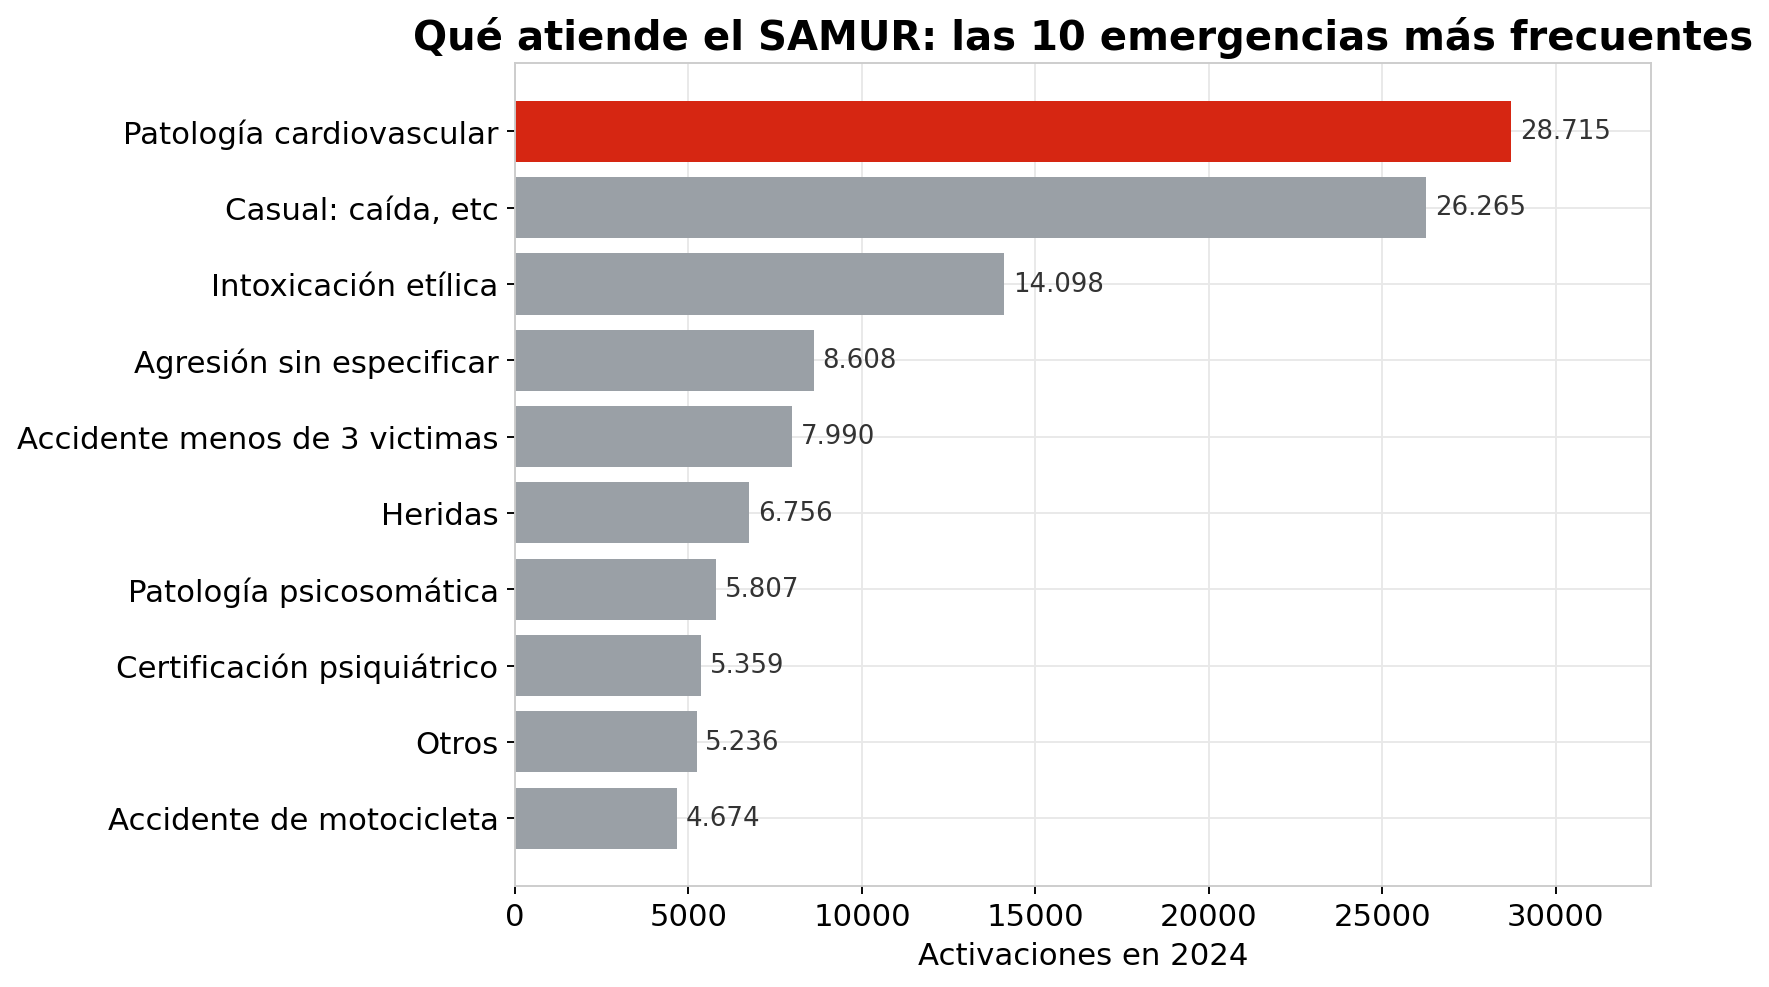


Prioridad del catálogo (gravedad típica del tipo):
  alta: 57.894 (40%)
  media: 68.100 (46%)
  baja: 20.573 (14%)


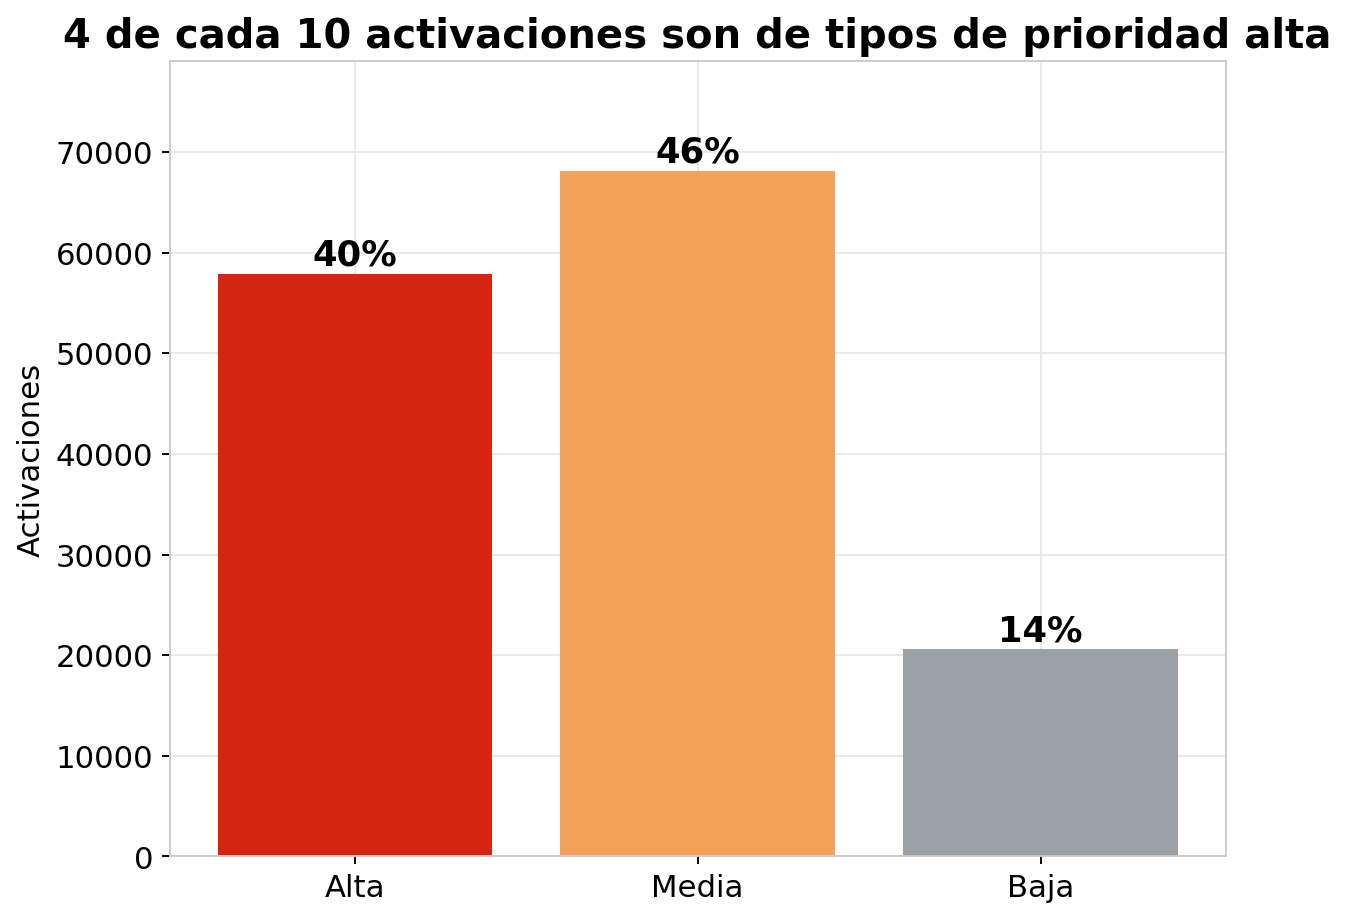

In [8]:
top10 = act['tipo_figura'].value_counts().head(10).sort_values()
print("Top 3:")
for t, n in act['tipo_figura'].value_counts().head(3).items():
    print(f"  {t}: {n:,} ({n/len(act)*100:.0f}%)".replace(',', '.'))

fig, ax = plt.subplots(figsize=(10, 6))
colores = [ROJO if t == top10.index[-1] else GRIS for t in top10.index]
ax.barh(top10.index, top10.values, color=colores)
ax.set_xlabel('Activaciones en 2024')
ax.set_title('Qué atiende el SAMUR: las 10 emergencias más frecuentes')
for i, v in enumerate(top10.values):
    ax.text(v + 250, i, f'{v:,}'.replace(',', '.'), va='center', fontsize=11, color='#333333')
ax.set_xlim(0, top10.max() * 1.14)
plt.tight_layout()
plt.savefig('graficos_eda/tipos_emergencia_top10.png', bbox_inches='tight')
plt.show()

pri = act['prioridad'].value_counts().reindex(['alta', 'media', 'baja'])
print()
print("Prioridad del catálogo (gravedad típica del tipo):")
for p, n in pri.items():
    print(f"  {p}: {n:,} ({n/pri.sum()*100:.0f}%)".replace(',', '.'))

fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.bar(['Alta', 'Media', 'Baja'], pri.values, color=[ROJO, '#f4a259', GRIS])
for i, v in enumerate(pri.values):
    ax.text(i, v + 900, f'{v/pri.sum()*100:.0f}%', ha='center', fontsize=15, fontweight='bold')
ax.set_ylabel('Activaciones')
ax.set_title('4 de cada 10 activaciones son de tipos de prioridad alta')
ax.set_ylim(0, pri.max() * 1.16)
plt.tight_layout()
plt.savefig('graficos_eda/prioridades.png', bbox_inches='tight')
plt.show()

**Lo que vemos:** patología cardiovascular (28.715) y caídas (26.265) concentran más de un tercio del servicio. El **40% de las activaciones son de tipos de prioridad alta** según el catálogo. Ojo: antes este porcentaje medía la prioridad registrada en cada evento; ahora mide la gravedad típica del tipo, que es lo que deja la limpieza (las dos solo coincidían en el 37,7% de las filas).

Decisión: los tipos se muestran con el código literal del catálogo, que es como vienen en `activaciones_limpio.csv` desde la última limpieza.

Un detalle que no esperábamos: la mediana del tiempo de respuesta apenas cambia con la prioridad del tipo (7,0 min en alta, 7,1 en media y 7,6 en baja). El tiempo mide desde la solicitud hasta la intervención, así que no vemos si las urgentes se cuelan antes en la cola; lo apuntamos como pregunta para Bluetab, no como conclusión.

## 6. A quién atiende el SAMUR: la edad publicada no es fiable

Perfil del paciente: edad y sexo. Aquí nos hemos llevado una sorpresa que hay que contar.

Al pintar la edad vemos que está repartida de forma **casi uniforme entre 0 y 99** (unas 1.500 activaciones por cada edad). En datos reales de emergencias no es lo habitual: normalmente pesan más los mayores y los muy pequeños. No sabemos el motivo: puede ser anonimización, cómo se publica el dato o un problema de registro. Es un **patrón que hay que validar con Bluetab**, no podemos afirmar la causa.

Decisión (de precaución, no porque esté demostrado que el dato es falso): mientras no se valide, no usamos la edad del paciente para sacar insights. El cruce por distrito de la sección 7 usa el % de mayores del censo, que viene de otra fuente.

Sexo: 70.675 mujeres y 70.093 hombres (prácticamente 50/50)
Edades distintas: 100 (de 0 a 99)
Media de activaciones por edad: 1457 (si fuera uniforme perfecta)
Mínimo y máximo por edad: 1325 - 1521 (diferencia del 13%)


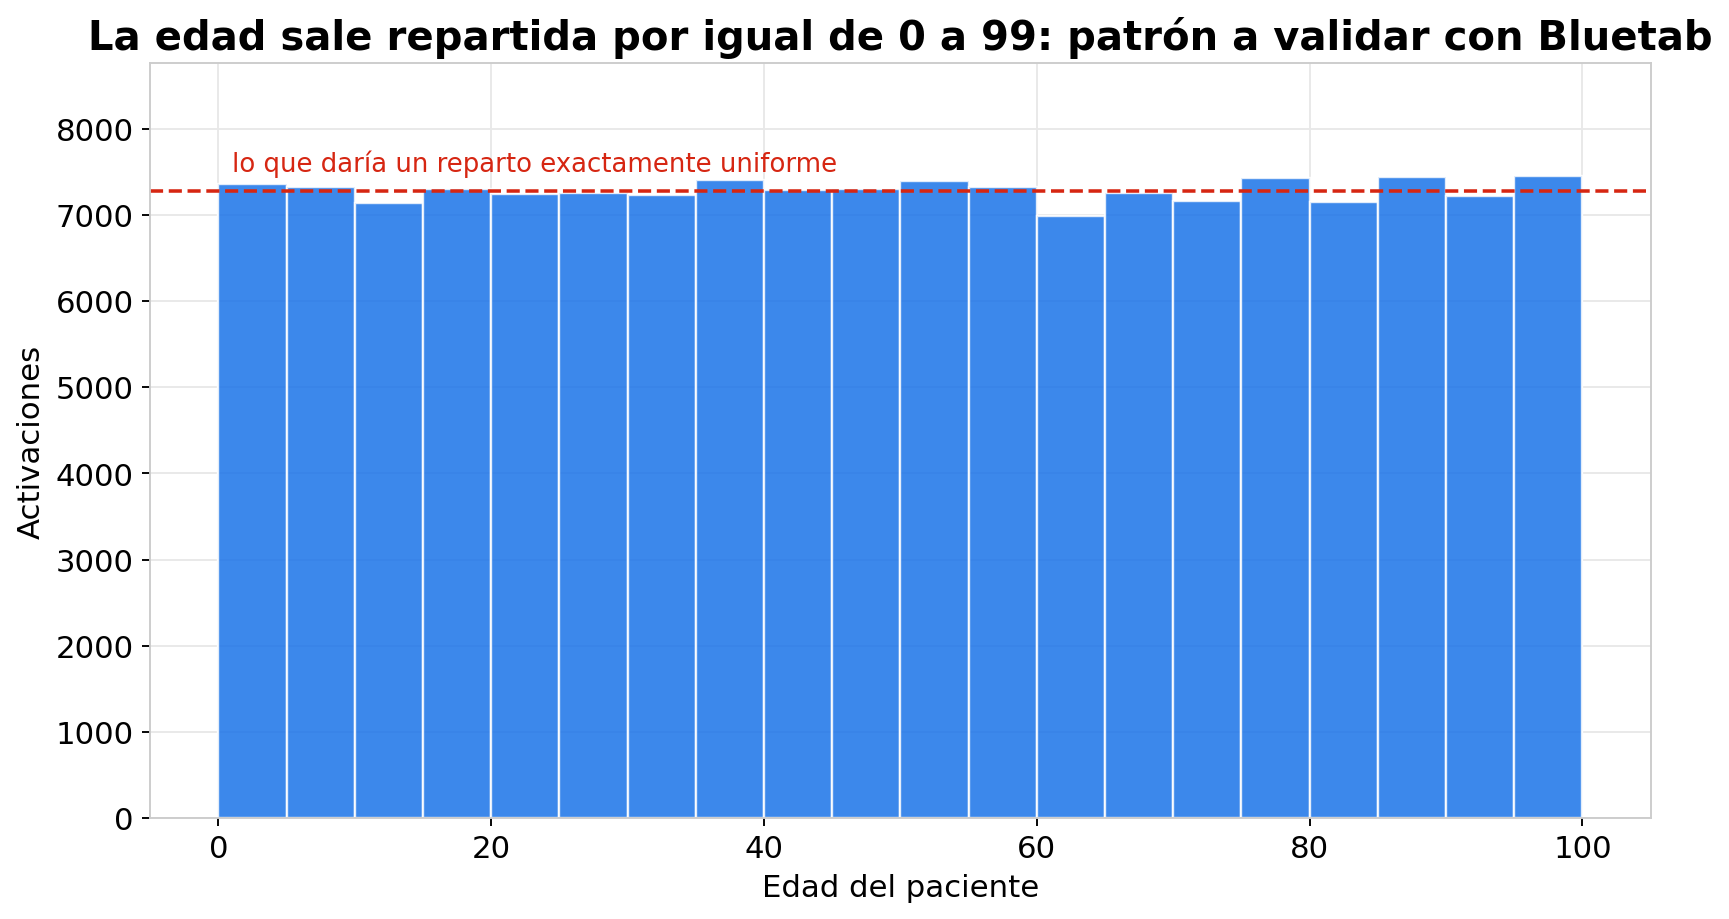

In [9]:
edad = act['paciente_edad'].dropna()
sexo = act['paciente_sexo'].value_counts()
print(f"Sexo: {sexo.get('M', 0):,} mujeres y {sexo.get('H', 0):,} hombres (prácticamente 50/50)".replace(',', '.'))

# Comprobación: activaciones por cada edad concreta (0-99)
por_edad = edad.value_counts()
print(f"Edades distintas: {edad.nunique()} (de {edad.min():.0f} a {edad.max():.0f})")
print(f"Media de activaciones por edad: {len(edad)/edad.nunique():.0f} (si fuera uniforme perfecta)")
print(f"Mínimo y máximo por edad: {por_edad.min()} - {por_edad.max()} (diferencia del {(por_edad.max()-por_edad.min())/por_edad.mean()*100:.0f}%)")

fig, ax = plt.subplots()
ax.hist(edad, bins=range(0, 105, 5), color=AZUL, alpha=0.85, edgecolor='white')
ax.axhline(len(edad)/edad.nunique()*5, color=ROJO, linestyle='--', linewidth=1.5)
ax.text(1, len(edad)/edad.nunique()*5*1.03, 'lo que daría un reparto exactamente uniforme', color=ROJO, fontsize=11)
ax.set_xlabel('Edad del paciente')
ax.set_ylabel('Activaciones')
ax.set_title('La edad sale repartida por igual de 0 a 99: patrón a validar con Bluetab')
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
plt.tight_layout()
plt.savefig('graficos_eda/edad_pacientes.png', bbox_inches='tight')
plt.show()

**Lo que vemos:** el reparto es plano de punta a punta (cada edad se desvía poco del uniforme exacto) y el sexo sale 50/50 casi perfecto (70.675 mujeres vs 70.093 hombres). La lectura honesta: **hasta validarlo con Bluetab, edad y sexo del paciente no se prestan a conclusiones**. Queda apuntado como pregunta y como limitación del análisis por paciente.

## 7. Dónde: la demanda no se reparte igual

Cruzamos con `tabla_distritos.csv`. Para comparar distritos de distinto tamaño usamos **activaciones por 1.000 residentes** (activaciones por población residente) (decisión ya tomada en los cruces: si no, los distritos grandes parecerían peores solo por tener más gente).

Centro es un caso aparte: 141 activaciones por 1.000 residentes, 3,1 veces la media simple de los 21 distritos (45) y 2,2 veces el segundo distrito (Moncloa-Aravaca, 65). Miramos si su perfil de activaciones apunta a una explicación.

Centro: 141 activaciones/1.000 residentes
Media simple de los 21 distritos: 45 | ratio agregado de la ciudad: 44
Centro es 3.1x la media de distritos y 2.2x el segundo (Moncloa-Aravaca, 65)
Activaciones de 0 a 7h: Centro 24% vs resto 15%
Intoxicación etílica: Centro 14% vs resto 9%


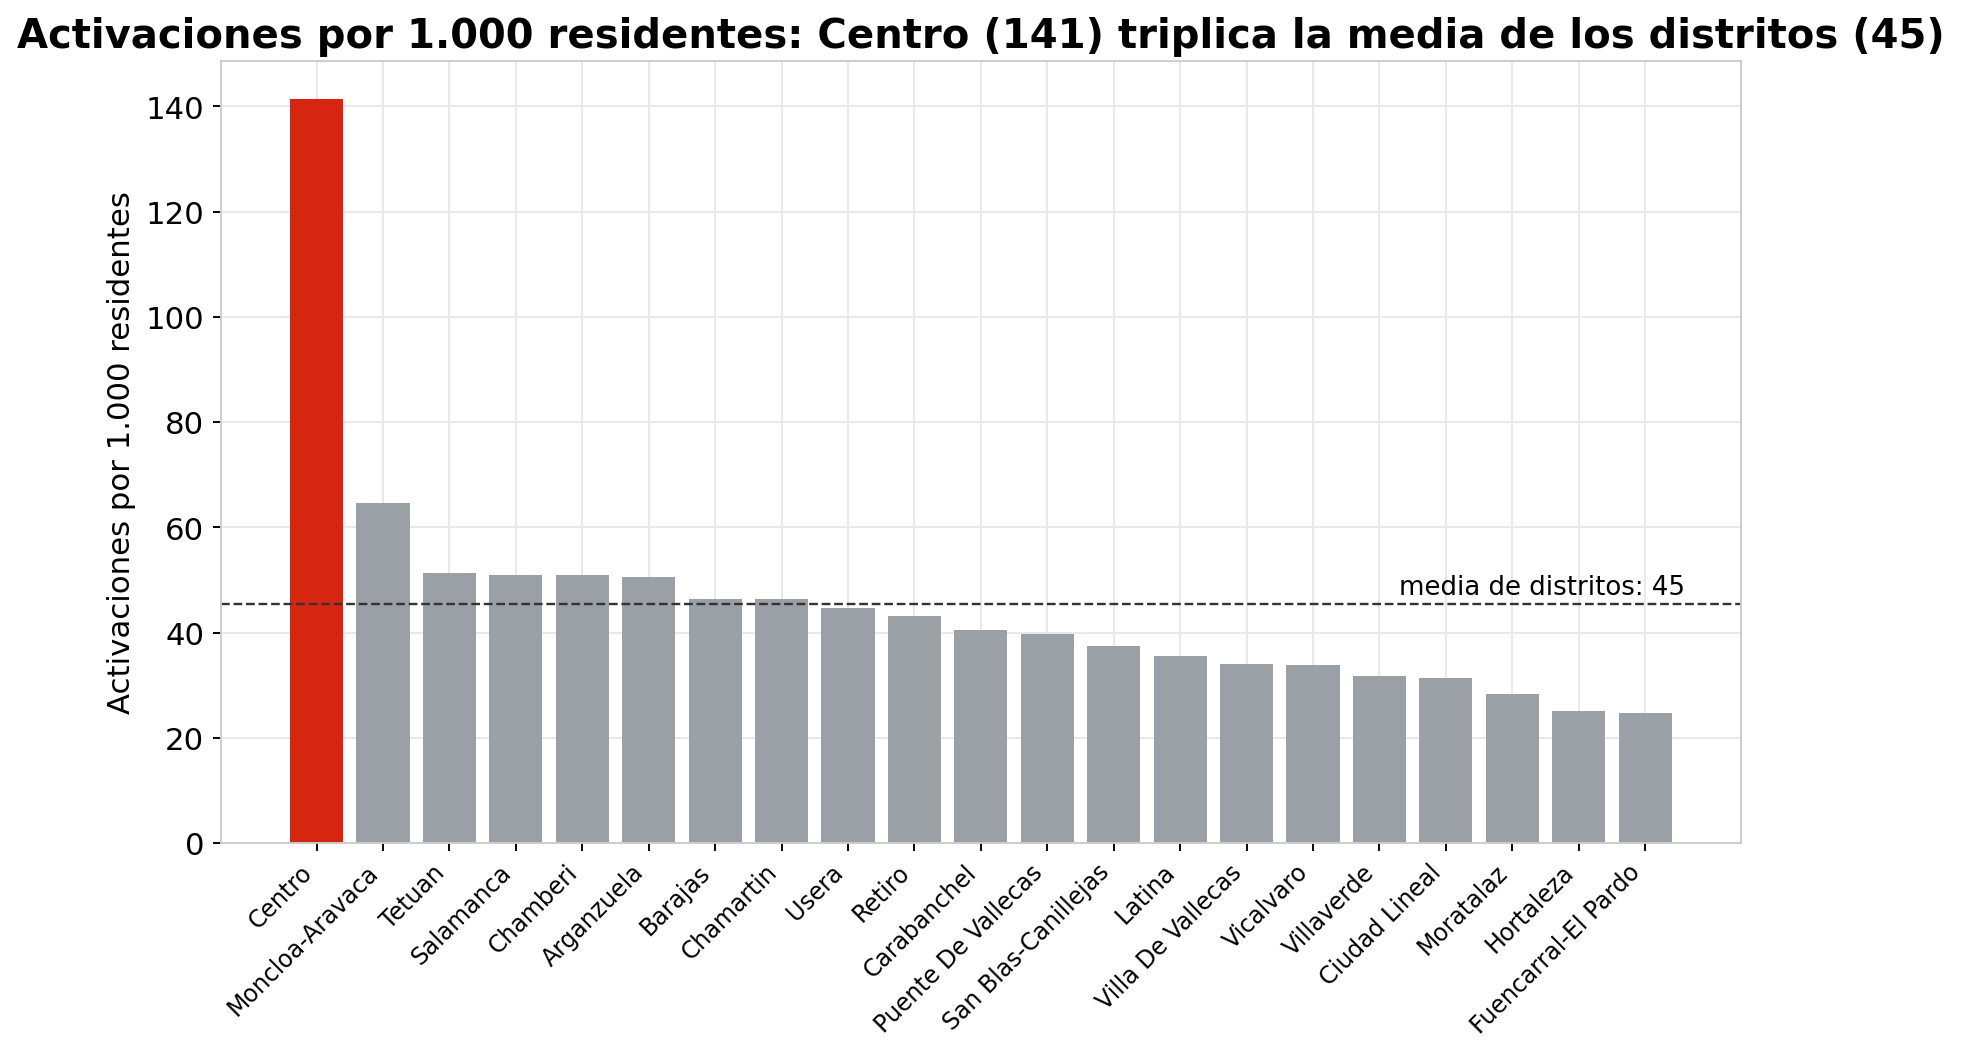

In [10]:
t = tabla.sort_values('activaciones_por_1000hab', ascending=False)
media_distritos = t['activaciones_por_1000hab'].mean()  # media simple de los 21 distritos
ratio_ciudad = t['n_activaciones'].sum() / t['poblacion'].sum() * 1000  # ratio agregado de la ciudad
centro = t.iloc[0]
segundo = t.iloc[1]
print(f"Centro: {centro['activaciones_por_1000hab']:.0f} activaciones/1.000 residentes")
print(f"Media simple de los 21 distritos: {media_distritos:.0f} | ratio agregado de la ciudad: {ratio_ciudad:.0f}")
print(f"Centro es {centro['activaciones_por_1000hab']/media_distritos:.1f}x la media de distritos y {centro['activaciones_por_1000hab']/segundo['activaciones_por_1000hab']:.1f}x el segundo ({segundo['distrito'].title()}, {segundo['activaciones_por_1000hab']:.0f})")

# Perfil de Centro: de madrugada y ocio
ce = act[act['distrito'] == 'CENTRO']
resto = act[act['distrito'] != 'CENTRO']
noche_ce = ((ce['hora'] >= 0) & (ce['hora'] < 7)).mean() * 100
noche_re = ((resto['hora'] >= 0) & (resto['hora'] < 7)).mean() * 100
ie_ce = (ce['tipo_emergencia'] == 'Intoxicación etílica').mean() * 100
ie_re = (resto['tipo_emergencia'] == 'Intoxicación etílica').mean() * 100
print(f"Activaciones de 0 a 7h: Centro {noche_ce:.0f}% vs resto {noche_re:.0f}%")
print(f"Intoxicación etílica: Centro {ie_ce:.0f}% vs resto {ie_re:.0f}%")

fig, ax = plt.subplots(figsize=(10, 6.4))
colores = [ROJO if d == 'CENTRO' else GRIS for d in t['distrito']]
ax.bar(range(len(t)), t['activaciones_por_1000hab'], color=colores)
ax.axhline(media_distritos, color='#333333', linestyle='--', linewidth=1)
ax.text(len(t) - 0.4, media_distritos + 2, f'media de distritos: {media_distritos:.0f}', ha='right', fontsize=11)
ax.set_xticks(range(len(t)))
ax.set_xticklabels(t['distrito'].str.title(), rotation=45, ha='right', fontsize=10)
ax.set_ylabel('Activaciones por 1.000 residentes')
ax.set_title(f'Activaciones por 1.000 residentes: Centro ({centro["activaciones_por_1000hab"]:.0f}) triplica la media de los distritos ({media_distritos:.0f})')
plt.tight_layout()
plt.savefig('graficos_eda/demanda_por_distrito.png', bbox_inches='tight')
plt.show()

Centro concentra el **24% de sus activaciones entre las 0 y las 7h** (en el resto de la ciudad, el 15%) y una vez y media las intoxicaciones etílicas (14% vs 9%). La hipótesis es clara: su demanda la dispara el ocio nocturno y la afluencia de gente que no vive ahí, no solo sus vecinos.

Ojo con el denominador: la población es de **residentes**, pero la activación ocurre donde está la persona en ese momento. En Centro buena parte de la demanda será de gente de paso (ocio, turismo, trabajo), no de vecinos, así que su ratio no se puede leer como "riesgo del vecino". En distritos más residenciales la lectura es más limpia.

¿Y la renta? En estos 21 distritos **no se ve** la relación del tópico "más vulnerabilidad, más emergencias": la correlación entre activaciones por población residente y renta media sale positiva (0,19 con Centro, 0,41 dejándolo fuera; damos los dos números porque un solo distrito mueve mucho el resultado). No es una ley general: es lo que muestran estos datos. Una lectura plausible es que los distritos con más renta son también los más envejecidos según el censo (Salamanca, Chamartín), y las activaciones por población residente también suben con el % de mayores de 65 del distrito (0,38 sin Centro). No lo podemos confirmar con la edad del paciente, que está pendiente de validar. Aun así, son 21 puntos y una correlación: lo tratamos como hipótesis para el clustering, no como conclusión.

Correlación demanda-renta: 0.19 con Centro, 0.41 sin Centro
Correlación demanda-%mayores65 (sin Centro): 0.38
Correlación demanda-vulnerabilidad (sin Centro): -0.36


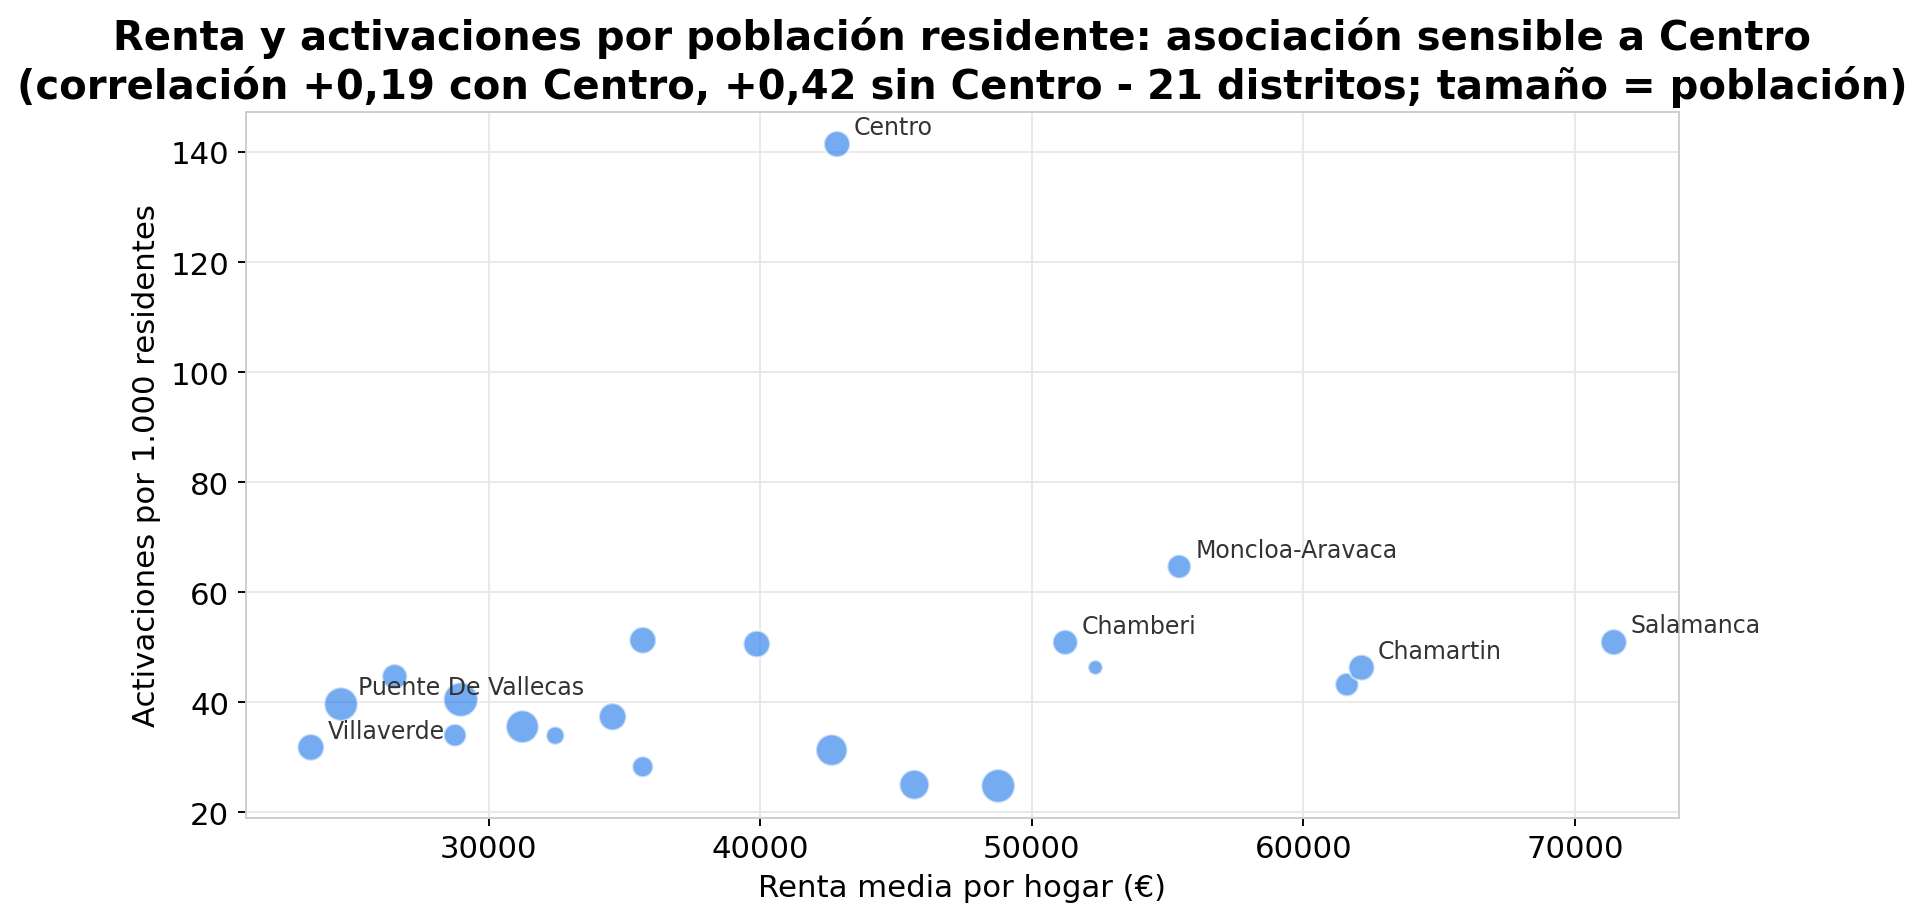

In [11]:
t2 = tabla[tabla['distrito'] != 'CENTRO']
r_con = tabla['activaciones_por_1000hab'].corr(tabla['renta_media_hogar'])
r_sin = t2['activaciones_por_1000hab'].corr(t2['renta_media_hogar'])
print(f"Correlación demanda-renta: {r_con:.2f} con Centro, {r_sin:.2f} sin Centro")
print(f"Correlación demanda-%mayores65 (sin Centro): {t2['activaciones_por_1000hab'].corr(t2['pct_mayores_65']):.2f}")
print(f"Correlación demanda-vulnerabilidad (sin Centro): {t2['activaciones_por_1000hab'].corr(t2['indice_vulnerabilidad']):.2f}")

fig, ax = plt.subplots()
ax.scatter(tabla['renta_media_hogar'], tabla['activaciones_por_1000hab'],
           s=tabla['poblacion'] / 1200, color=AZUL, alpha=0.6, edgecolor='white', linewidth=1)
for _, f in tabla.iterrows():
    if f['distrito'] in ('CENTRO', 'SALAMANCA', 'VILLAVERDE', 'PUENTE DE VALLECAS', 'MONCLOA-ARAVACA', 'CHAMARTIN', 'CHAMBERI'):
        ax.annotate(f['distrito'].title(), (f['renta_media_hogar'], f['activaciones_por_1000hab']),
                    textcoords='offset points', xytext=(7, 4), fontsize=10, color='#333333')
ax.set_xlabel('Renta media por hogar (€)')
ax.set_ylabel('Activaciones por 1.000 residentes')
ax.set_title('Renta y activaciones por población residente: asociación sensible a Centro\n(correlación +0,19 con Centro, +0,42 sin Centro - 21 distritos; tamaño = población)')
plt.tight_layout()
plt.savefig('graficos_eda/renta_vs_demanda.png', bbox_inches='tight')
plt.show()

## 8. El tiempo de respuesta: la densidad manda

La otra cara del servicio: cuánto se tarda en llegar. Usamos `tiempo_de_respuesta` (solicitud → intervención, con la regla de medianoche aplicada en la limpieza; antes se llamaba `tiempo_respuesta_min`).

Mediana: 7.2 min | media: 7.7 min
El 60% de las activaciones se atiende en 8 minutos o menos
Percentil 90: 12 min
Más rápido: CHAMBERI (6.5 min)
Más lento: BARAJAS (10.7 min)
Correlación con la densidad: -0.87


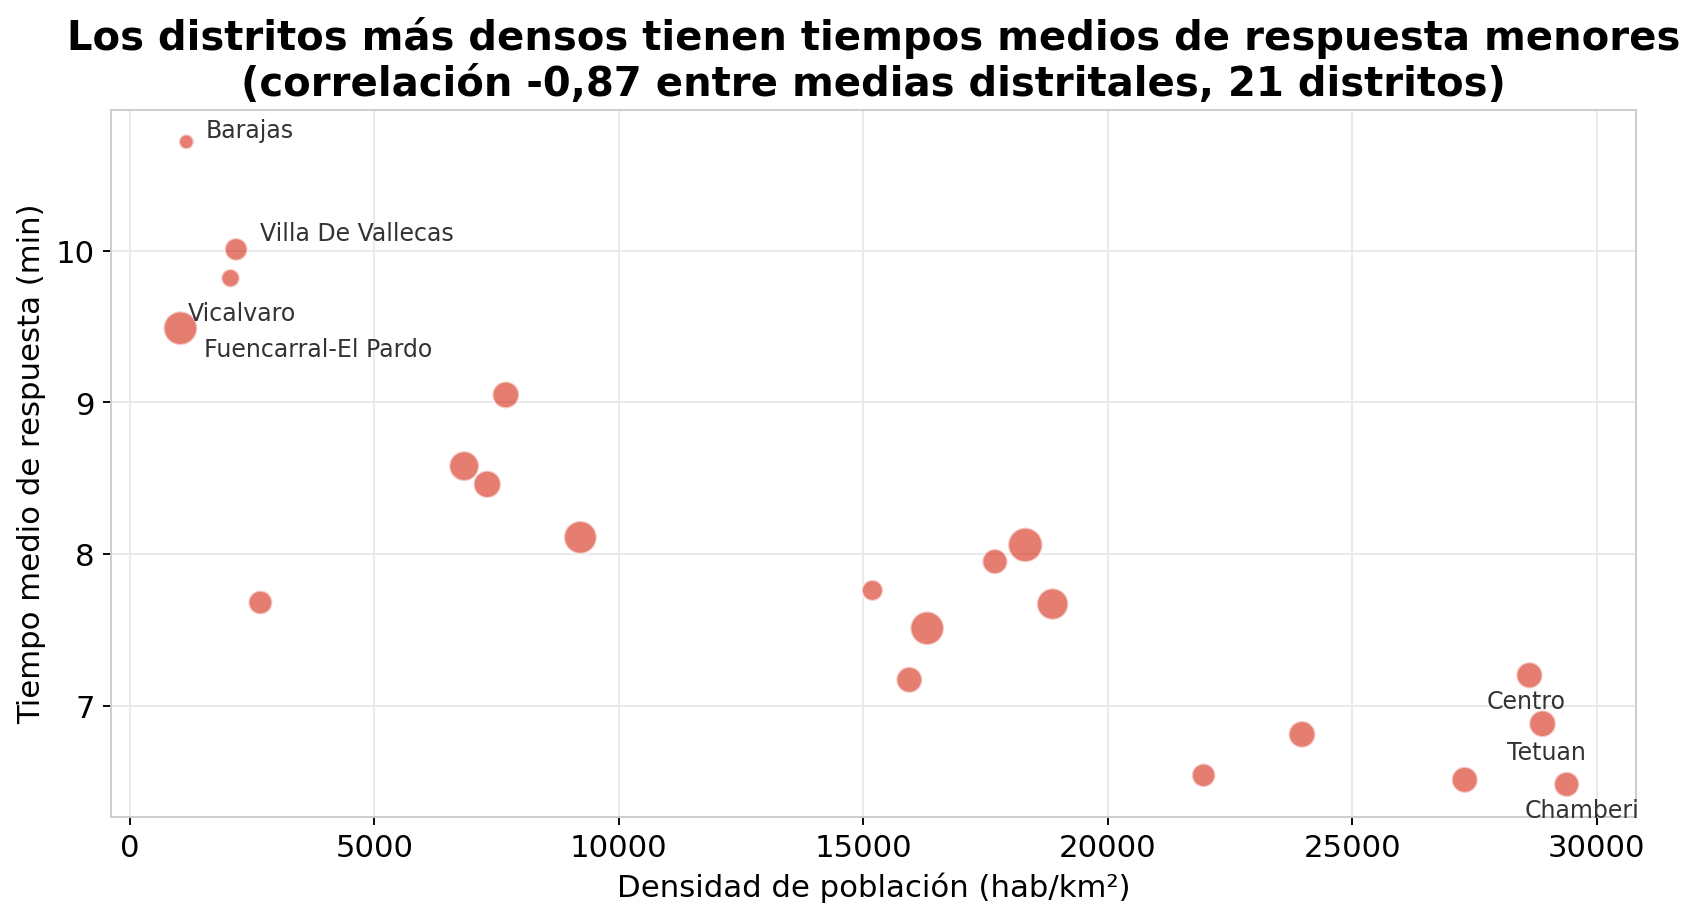

In [12]:
tr = act['tiempo_de_respuesta'].dropna()
print(f"Mediana: {tr.median():.1f} min | media: {tr.mean():.1f} min")
print(f"El {(tr <= 8).mean()*100:.0f}% de las activaciones se atiende en 8 minutos o menos")
print(f"Percentil 90: {tr.quantile(0.9):.0f} min")

por_distrito = tabla[['distrito', 'tiempo_respuesta_medio_min', 'densidad_hab_km2']].sort_values('tiempo_respuesta_medio_min')
rapido = por_distrito.iloc[0]
lento = por_distrito.iloc[-1]
print(f"Más rápido: {rapido['distrito']} ({rapido['tiempo_respuesta_medio_min']:.1f} min)")
print(f"Más lento: {lento['distrito']} ({lento['tiempo_respuesta_medio_min']:.1f} min)")
print(f"Correlación con la densidad: {tabla['tiempo_respuesta_medio_min'].corr(tabla['densidad_hab_km2']):.2f}")

fig, ax = plt.subplots()
ax.scatter(tabla['densidad_hab_km2'], tabla['tiempo_respuesta_medio_min'],
           s=tabla['poblacion'] / 1200, color=ROJO, alpha=0.6, edgecolor='white', linewidth=1)
for _, f in tabla.iterrows():
    etq = {'BARAJAS': (8, 2), 'CHAMBERI': (-18, -14), 'FUENCARRAL-EL PARDO': (8, -6),
           'CENTRO': (-18, -14), 'VILLA DE VALLECAS': (10, 4), 'VICALVARO': (-18, -18), 'FUENCARRAL-EL PARDO': (10, -12), 'TETUAN': (-15, -15)}
    if f['distrito'] in etq:
        ax.annotate(f['distrito'].title(), (f['densidad_hab_km2'], f['tiempo_respuesta_medio_min']),
                    textcoords='offset points', xytext=etq[f['distrito']], fontsize=10, color='#333333')
ax.set_xlabel('Densidad de población (hab/km²)')
ax.set_ylabel('Tiempo medio de respuesta (min)')
ax.set_title('Los distritos más densos tienen tiempos medios de respuesta menores\n(correlación -0,87 entre medias distritales, 21 distritos)')
plt.tight_layout()
plt.savefig('graficos_eda/densidad_vs_tiempo_respuesta.png', bbox_inches='tight')
plt.show()

**Lo que vemos:** la mitad de las activaciones se atiende en **7 minutos o menos** (el 60% en 8), pero la diferencia entre distritos es grande: de 6,5 min en Chamberí a 10,7 min en Barajas. La correlación entre densidad y tiempo medio de respuesta es **-0,87**, la asociación más fuerte de todo el análisis. Es una correlación entre medias de 21 distritos, no una prueba causal; la lectura plausible (en distritos densos las unidades están físicamente más cerca) es una hipótesis. Los distritos dispersos de la periferia (Barajas, Villa de Vallecas, Vicálvaro, Fuencarral) son los que más esperan, y ahí el cuello de botella parece geográfico, no de volumen.

Como hipótesis de trabajo es sólida y va directa al objetivo del proyecto (dónde hacen falta recursos).

## 9. Oferta y demanda: la red funciona como red

Último cruce: ¿los distritos con más recursos son los de más demanda? Comparando unidades SAMUR con base en cada distrito frente a su demanda por habitante.

Aquí el dato clave, con el denominador claro: de las 113.905 activaciones con unidad y distrito identificados (el 78% del total; fuera quedan 601 sin distrito asignable y 32.061 atendidas por unidades cuya base no tiene distrito seguro), **solo el 5,8% las atiende una unidad con base en el mismo distrito de la activación**. Y mirando solo los 7 distritos que tienen unidades con base propia (51.156 activaciones identificadas), el porcentaje sube solo al 13%. Es decir: la base registrada no dice dónde trabaja cada unidad, y los datos encajan con una gestión en red de la ciudad (el dato no dice qué zona cubre cada unidad). En esa línea, distritos sin base propia (como Chamberí) tienen tiempos de respuesta buenos.

Dos matices honestos: que la base de la unidad esté en otro distrito no significa que la unidad no cubra esa zona (los recorridos no están en el dato), y 32.061 activaciones (22%) las atienden unidades cuya base no se puede asignar a un distrito: 10 unidades del catálogo tienen la base `VALLECAS` a secas, que no distingue Puente de Villa de Vallecas, y 5 la tienen `NO CONSTA` o vacía. Por eso Puente y Villa de Vallecas no salen en el gráfico: sus unidades son desconocidas, no 0.

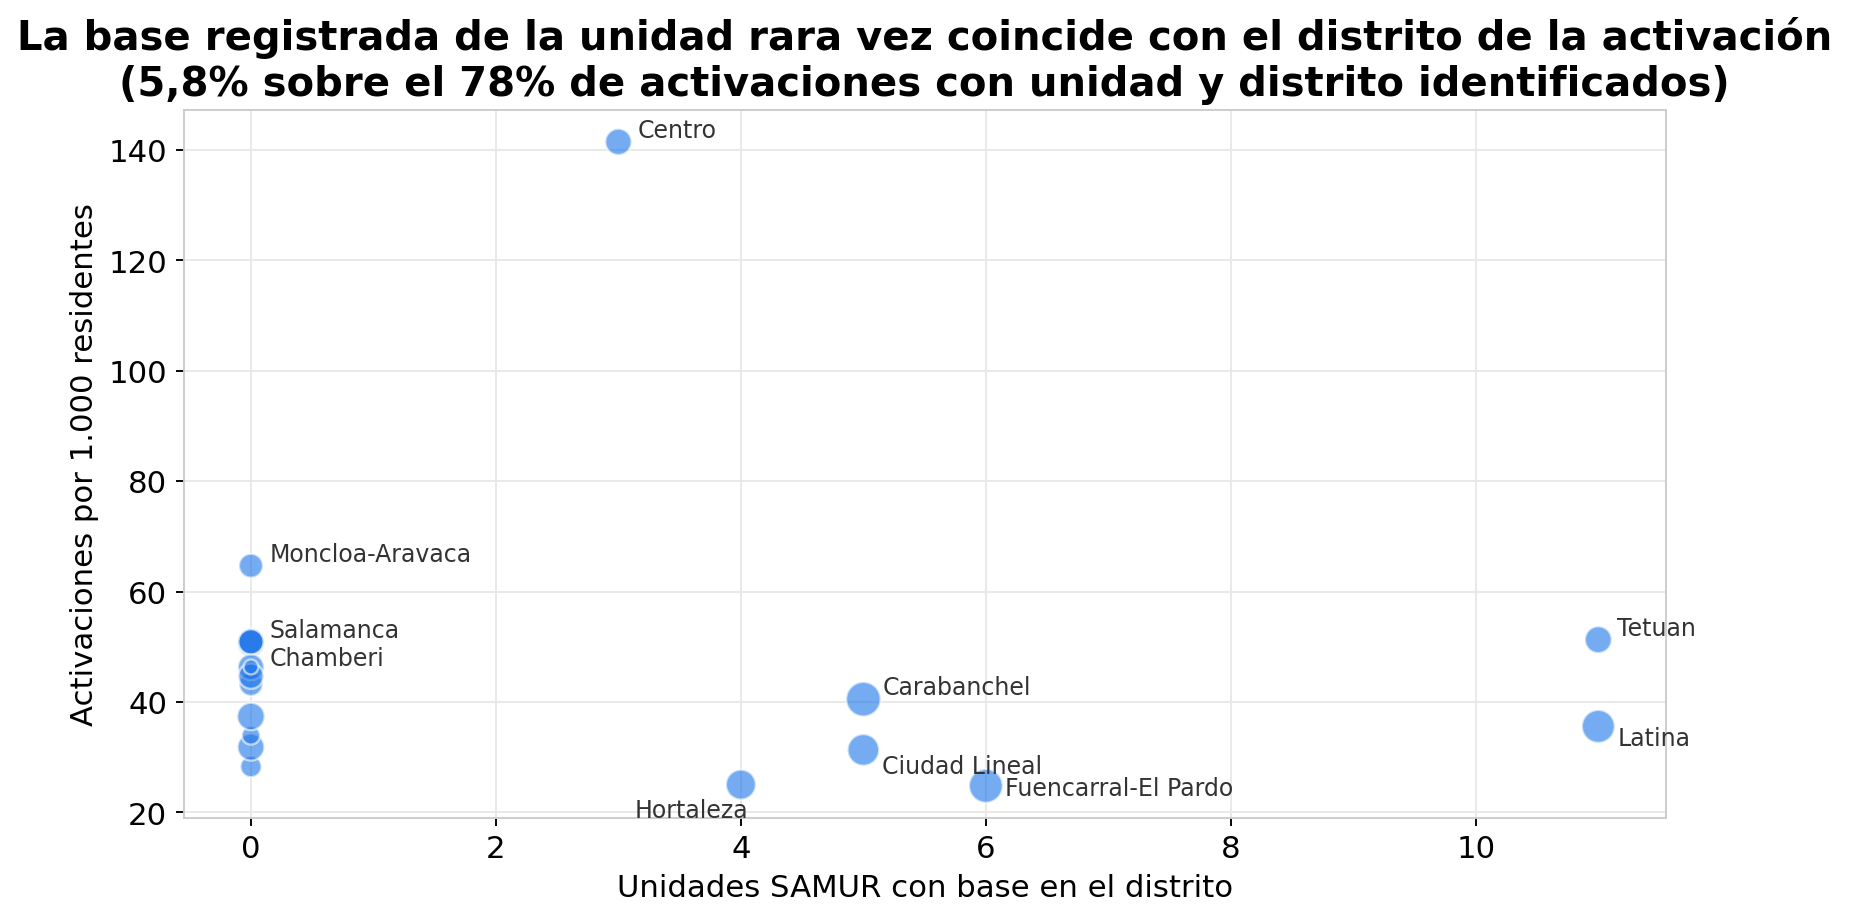

Ejemplos:
  Centro: 3.0 unidades, 141 act./1.000 hab, 7.2 min de respuesta
  Tetuan: 11.0 unidades, 51 act./1.000 hab, 6.9 min de respuesta
  Latina: 11.0 unidades, 36 act./1.000 hab, 8.1 min de respuesta
  Chamberi: 0.0 unidades, 51 act./1.000 hab, 6.5 min de respuesta
Fuera del gráfico: Puente y Villa de Vallecas (sus unidades son desconocidas, no 0)


In [13]:
tabla_od = tabla.dropna(subset=['unidades_samur'])  # fuera Puente y Villa de Vallecas: unidades desconocidas, no 0
fig, ax = plt.subplots()
ax.scatter(tabla_od['unidades_samur'], tabla_od['activaciones_por_1000hab'],
           s=tabla_od['poblacion'] / 1200, color=AZUL, alpha=0.6, edgecolor='white', linewidth=1)
etiquetas = {'CENTRO': (8, 2), 'MONCLOA-ARAVACA': (8, 2), 'SALAMANCA': (8, 2),
             'CHAMBERI': (8, -10), 'TETUAN': (8, 2),
             'LATINA': (8, -8), 'CARABANCHEL': (8, 2), 'CIUDAD LINEAL': (8, -10),
             'FUENCARRAL-EL PARDO': (8, -4), 'HORTALEZA': (-45, -14)}
for _, f in tabla_od.iterrows():
    if f['distrito'] in etiquetas:
        ax.annotate(f['distrito'].title(), (f['unidades_samur'], f['activaciones_por_1000hab']),
                    textcoords='offset points', xytext=etiquetas[f['distrito']], fontsize=10, color='#333333')
ax.set_xlabel('Unidades SAMUR con base en el distrito')
ax.set_ylabel('Activaciones por 1.000 residentes')
ax.set_title('La base registrada de la unidad rara vez coincide con el distrito de la activación\n(5,8% sobre el 78% de activaciones con unidad y distrito identificados)')
plt.tight_layout()
plt.savefig('graficos_eda/oferta_vs_demanda.png', bbox_inches='tight')
plt.show()

print("Ejemplos:")
for d in ['CENTRO', 'TETUAN', 'LATINA', 'CHAMBERI']:
    f = tabla[tabla['distrito'] == d].iloc[0]
    print(f"  {d.title()}: {f['unidades_samur']} unidades, {f['activaciones_por_1000hab']:.0f} act./1.000 hab, {f['tiempo_respuesta_medio_min']:.1f} min de respuesta")
print("Fuera del gráfico: Puente y Villa de Vallecas (sus unidades son desconocidas, no 0)")

## 10. Mapas de distritos: actividad, tiempo de respuesta y contexto social

Hasta aquí hemos visto los distritos en gráficos de barras y de puntos. Los mapas responden a una pregunta que esos gráficos no enseñan bien: **dónde está cada cosa en Madrid**. Son tres, y cada uno se apoya en el anterior:

1. **Actividad frente a tiempo de respuesta** (dos mapas lado a lado): dónde se concentran las activaciones y dónde tarda más la respuesta.
2. **Mapa bivariante:** las dos variables juntas, para ver qué distritos combinan actividad alta o baja con respuesta rápida o lenta.
3. **Contexto social:** renta, vulnerabilidad y población mayor de 65, como marco para el clustering.

Usan solo la tabla por distrito del proyecto (`tabla_distritos.csv`, 21 filas, ya cargada arriba como `tabla`). No repiten la limpieza ni usan puntos por emergencia: el dato abierto no trae la ubicación exacta.

### 10.1 Datos y límites oficiales

Los límites de distrito vienen del servicio de mapas oficial del Ayuntamiento de Madrid (capa DISTRITOS, ETRS89 / UTM 30N, término municipal, no Comunidad). Se descargan al ejecutar, no se dibujan a mano. Se une por el código de distrito (1 a 21) y no por el nombre, porque los nombres se escriben distinto según la fuente (decisión coherente con los problemas de nombres que ya vimos en la limpieza).

Decisión: antes de dibujar los mapas restablecemos el estilo de matplotlib a los valores por defecto, porque el estilo de las secciones anteriores (cuadrícula, tamaño de letra) está pensado para gráficos de ejes y estropea los mapas.

In [14]:
import json, numpy as np, pandas as pd, matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MPath
from matplotlib.colors import Normalize, to_rgb
from matplotlib import cm
from shapely.geometry import shape
plt.rcdefaults()  # estilo por defecto: el de las secciones anteriores no sirve para mapas
plt.rcParams.update({"font.family":"DejaVu Sans"})
import os, urllib.request, urllib.parse
t=tabla.copy(); t["cod"]=t.distrito_id  # misma tabla ya cargada arriba
# Límites oficiales: servicio de mapas del Ayuntamiento de Madrid, capa DISTRITOS, ETRS89 / UTM 30N (EPSG:25830)
URL=("https://sigma.madrid.es/hosted/rest/services/CARTOGRAFIA/LIMITES_ADMINISTRATIVOS/MapServer/3/query?"
     +urllib.parse.urlencode({"where":"1=1","outFields":"COD_DIS_TX,NOMBRE","outSR":25830,"f":"geojson"}))
if not os.path.exists("distritos_madrid.geojson"):
    urllib.request.urlretrieve(URL,"distritos_madrid.geojson")
g=json.load(open("distritos_madrid.geojson"))
geo={int(f["properties"]["COD_DIS_TX"]):(shape(f["geometry"]),f["properties"]["NOMBRE"]) for f in g["features"]}
assert sorted(geo)==list(t.cod) and len(t)==21
t["nombre"]=t.cod.map(lambda c:geo[c][1])
short={"Fuencarral - El Pardo":"Fuencarral\nEl Pardo","Moncloa - Aravaca":"Moncloa\nAravaca","San Blas - Canillejas":"San Blas\nCanillejas","Puente de Vallecas":"Puente de\nVallecas","Villa de Vallecas":"Villa de\nVallecas","Ciudad Lineal":"Ciudad\nLineal"}
t["lab"]=t.nombre.map(lambda n:short.get(n,n))
INK="#1f2933"; BG="#ffffff"
def patch(poly,fc,lw=1.0,ec="white"):
    verts=[];codes=[]
    for ring in [poly.exterior]+list(poly.interiors):
        xy=np.array(ring.coords);verts+=list(xy);codes+=[MPath.MOVETO]+[MPath.LINETO]*(len(xy)-2)+[MPath.CLOSEPOLY]
    return PathPatch(MPath(verts,codes),fc=fc,ec=ec,lw=lw)
CORE=[1,2,3,4,5,6,7,14,15]
def _fill(ax,colors):
    for _,r in t.iterrows(): ax.add_patch(patch(geo[r.cod][0],colors[r.cod]))
def _lab(ax,labels,txtcol,fs,codes):
    for c in codes:
        p=geo[c][0].representative_point()
        ax.text(p.x,p.y,labels[c],ha="center",va="center",fontsize=fs,color=(txtcol[c] if txtcol else INK),fontweight="bold",linespacing=1.05)
def draw(ax,colors,labels=None,fs=7.5,txtcol=None,ifs=7.5):
    _fill(ax,colors)
    b=[geo[c][0].bounds for c in geo]
    x0=min(x[0] for x in b);y0=min(x[1] for x in b);x1=max(x[2] for x in b);y1=max(x[3] for x in b)
    w=x1-x0
    ax.set_xlim(x0-500,x1+0.40*w);ax.set_ylim(y0-500,y1+500);ax.set_aspect("equal");ax.axis("off")
    if labels is None: return
    _lab(ax,labels,txtcol,fs,[c for c in geo if c not in CORE])
    ys={c:geo[c][0].representative_point() for c in CORE}
    order=sorted(CORE,key=lambda c:-ys[c].y)
    yc=np.mean([p.y for p in ys.values()]);span=(y1-y0)*0.075
    xs=x1+0.03*w
    for k,c in enumerate(order):
        yy=yc+(len(order)/2-k-0.5)*span*1.0
        p=ys[c]
        ax.plot([p.x,xs],[p.y,yy],color="#3e4c59",lw=.7,zorder=5,solid_capstyle="round")
        ax.plot(p.x,p.y,"o",ms=3,color="#3e4c59",zorder=6,mec="white",mew=.6)
        col=colors[c];tcol=("white" if lum(col)<.5 else INK)
        ax.text(xs,yy,labels[c].replace("\n"," "),ha="left",va="center",fontsize=ifs,fontweight="bold",color=tcol,zorder=7,
                bbox=dict(boxstyle="round,pad=0.3",fc=col,ec="#3e4c59",lw=.6))
    ax.text(xs,yc+(len(order)/2)*span+span*.3,"Distritos centrales",fontsize=ifs,color="#52606d",ha="left",va="bottom",style="italic")

def lum(c): r,g_,b=to_rgb(c);return .299*r+.587*g_+.114*b
IMP={'renta_media_hogar':{3,15},'pct_mayores_65':{5,15},'indice_vulnerabilidad':{11,21}}
def choro(var,cmap,fmt,vmin=None,vmax=None):
    n=Normalize(vmin if vmin is not None else t[var].min(),vmax if vmax is not None else t[var].max())
    col={r.cod:cmap(n(r[var])) for _,r in t.iterrows()}
    lab={r.cod:r.lab+"\n"+fmt(r[var])+("*" if r.cod in IMP.get(var,()) else "") for _,r in t.iterrows()}
    tc={c:("white" if lum(col[c])<.5 else INK) for c in col}
    return n,col,lab,tc
def cbar(fig,ax,n,cmap,label,fmt=None):
    sm=cm.ScalarMappable(norm=n,cmap=cmap);cb=fig.colorbar(sm,ax=ax,orientation="horizontal",fraction=.035,pad=.01,aspect=35)
    fm=(lambda x:f'{x:,.0f}'.replace(',','.')) if n.vmax>100 else (lambda x:f'{x:.2f}' if n.vmax<2 else f'{x:.1f}');label=label+f'  (mín. {fm(n.vmin)} · máx. {fm(n.vmax)})';cb.set_label(label,fontsize=9,color=INK);cb.ax.tick_params(labelsize=8,colors=INK);cb.outline.set_visible(False)
SRC="Fuentes: activaciones SAMUR (limpias, proyecto Bluetab-UC3M 2024); población y renta: tabla_distritos.csv del proyecto; límites de distrito: Ayuntamiento de Madrid (Cartografía, ETRS89 / UTM 30N)."
def foot(fig,extra=""):
    fig.text(.5,.012,SRC+("\n"+extra if extra else ""),ha="center",va="bottom",fontsize=7.5,color="#52606d",linespacing=1.4)

### 10.2 Comprobaciones antes de dibujar

Los 21 códigos coinciden y la superficie del polígono oficial es parecida a la de la tabla. Si algo no encajara, el `assert` de arriba pararía el notebook en vez de dibujar un mapa con distritos mal unidos.

In [15]:
sup=pd.Series({c:geo[c][0].area/1e6 for c in geo})
chk=t.set_index("cod").superficie_km2
print("Distritos en tabla:",len(t),"| en cartografía:",len(geo),"| códigos iguales:",set(t.cod)==set(geo))
print("Diferencia máxima de superficie (km2, mapa vs tabla):",round((sup-chk).abs().max(),2))
print("Suma de activaciones en tabla:",int(t.n_activaciones.sum()))

Distritos en tabla: 21 | en cartografía: 21 | códigos iguales: True
Diferencia máxima de superficie (km2, mapa vs tabla): 0.67
Suma de activaciones en tabla: 145966


### 10.3 Mapa 1: actividad y tiempo de respuesta, lado a lado

**Pregunta:** ¿dónde se concentra la actividad del SAMUR y dónde tarda más la respuesta?

**Cómo está hecho:** activaciones por 1.000 residentes (mapa izquierdo) y tiempo medio de respuesta en minutos (mapa derecho), cada uno con su escala y su rango real (mínimo y máximo en la leyenda). Los distritos centrales son pequeños, así que sus etiquetas van aparte, unidas con una línea.

**Cómo leerlo:** cuanto más oscuro, mayor valor. Los dos mapas tienen escalas distintas y no se comparan color con color: se comparan posiciones.

**Qué vemos:** Centro destaca mucho en actividad (141 activaciones por 1.000 residentes, 3,5 veces la media simple de los otros 20 distritos, que es 41; después viene Moncloa-Aravaca con 65). En tiempo de respuesta pasa casi lo contrario: los más lentos están en el borde del municipio (Barajas 10,7 min, Villa de Vallecas 10,0, Vicálvaro 9,8) y el más rápido es Chamberí (6,5).

**Qué no dice:** la activación se cuenta en el distrito donde ocurre, no donde vive el paciente, y la población es de residentes. En Centro y Barajas la población presente no está medida, y eso puede afectar a la interpretación de la ratio (es una hipótesis sobre visitantes, no algo medido). El denominador de "3,5 veces" es la media simple de los otros 20 distritos; en la sección 7 la comparación era con los 21 (3,1 veces): mismo dato, distinto denominador. Un tiempo de respuesta largo tampoco demuestra falta de cobertura.

**Para qué sirve en el proyecto:** plantea las dos variables que tiene que capturar el clustering (demanda por habitante y tiempo de respuesta) y enseña que no van siempre juntas.

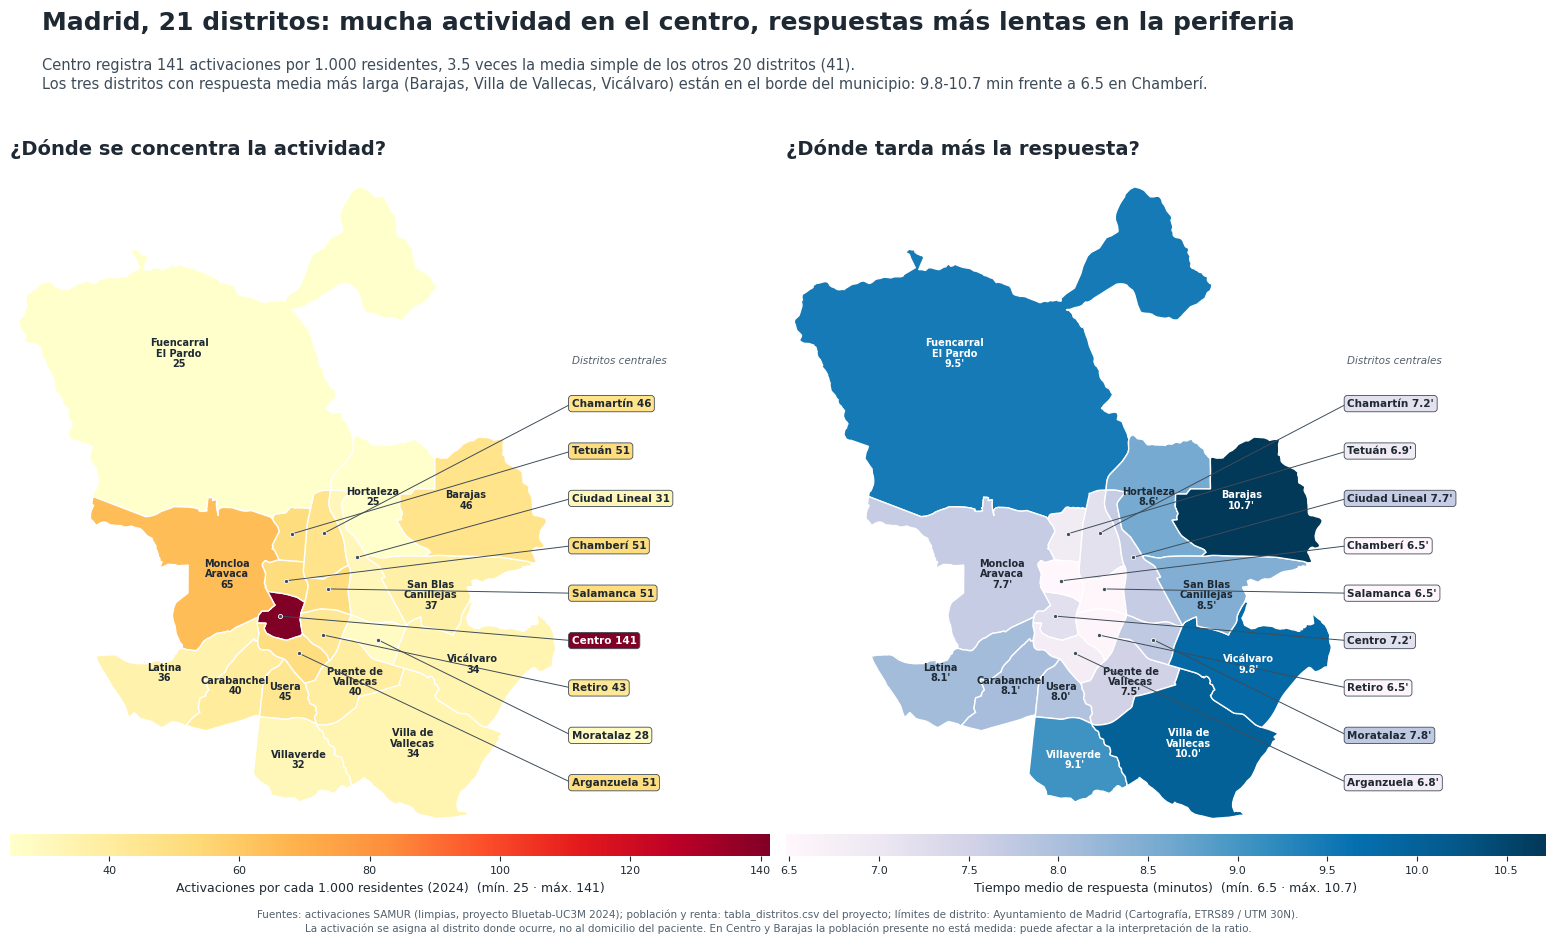

In [16]:
c1=plt.cm.YlOrRd; c2=plt.cm.PuBu
n1,col1,lab1,tc1=choro("activaciones_por_1000hab",c1,lambda v:f"{v:.0f}")
n2,col2,lab2,tc2=choro("tiempo_respuesta_medio_min",c2,lambda v:f"{v:.1f}'")
fig,axs=plt.subplots(1,2,figsize=(16,9.6),facecolor=BG)
draw(axs[0],col1,lab1,7,tc1,7.5);draw(axs[1],col2,lab2,7,tc2,7.5)
cbar(fig,axs[0],n1,c1,"Activaciones por cada 1.000 residentes (2024)");cbar(fig,axs[1],n2,c2,"Tiempo medio de respuesta (minutos)")
axs[0].set_title("¿Dónde se concentra la actividad?",fontsize=14,fontweight="bold",color=INK,loc="left")
axs[1].set_title("¿Dónde tarda más la respuesta?",fontsize=14,fontweight="bold",color=INK,loc="left")
top=t.nlargest(3,"activaciones_por_1000hab");slow=t.nlargest(3,"tiempo_respuesta_medio_min");fast=t.nsmallest(1,"tiempo_respuesta_medio_min").iloc[0]
tot=t.n_activaciones.sum()
fig.suptitle("Madrid, 21 distritos: mucha actividad en el centro, respuestas más lentas en la periferia",fontsize=18,fontweight="bold",color=INK,x=.04,ha="left",y=.975)
fig.text(.04,.925,f"Centro registra {top.iloc[0].activaciones_por_1000hab:.0f} activaciones por 1.000 residentes, {top.iloc[0].activaciones_por_1000hab/t[t.cod!=1].activaciones_por_1000hab.mean():.1f} veces la media simple de los otros 20 distritos ({t[t.cod!=1].activaciones_por_1000hab.mean():.0f}). "
 f"\nLos tres distritos con respuesta media más larga ({', '.join(slow.nombre)}) están en el borde del municipio: {slow.tiempo_respuesta_medio_min.min():.1f}-{slow.tiempo_respuesta_medio_min.max():.1f} min frente a {fast.tiempo_respuesta_medio_min:.1f} en {fast.nombre}.",
 fontsize=10.5,color="#3e4c59",ha="left",va="top")
foot(fig,"La activación se asigna al distrito donde ocurre, no al domicilio del paciente. En Centro y Barajas la población presente no está medida: puede afectar a la interpretación de la ratio.")
fig.subplots_adjust(left=.02,right=.98,top=.83,bottom=.09,wspace=.02)
fig.savefig("graficos_eda/mapa_demanda_vs_respuesta.png",dpi=130,facecolor=BG);plt.show()

### 10.4 Mapa 2: bivariante (actividad y tiempo de respuesta juntos)

**Pregunta:** si cruzamos las dos variables, ¿qué tipos de distrito aparecen?

**Cómo está hecho:** cada variable se divide en terciles (tres grupos de 7 distritos: bajo, medio, alto) y se combinan en una paleta de 3×3. Es una clasificación para visualizar, **no es un modelo de clustering**.

**Cómo leerlo:** el eje horizontal de la leyenda es la actividad por 1.000 residentes y el vertical, la lentitud de la respuesta. El título del mapa y el recuadro de la derecha dicen qué distritos caen en cada esquina.

**Qué vemos:** más actividad por habitante suele ir con respuesta media más rápida (Spearman -0,60, n = 21). Alta actividad y respuesta rápida: Centro, Arganzuela, Salamanca, Tetuán y Chamberí. Baja actividad y respuesta lenta: Fuencarral-El Pardo, Hortaleza, Villaverde, Villa de Vallecas y Vicálvaro. Alta actividad con respuesta lenta solo aparece en Barajas. El tiempo de respuesta se asocia todavía más con la densidad (Spearman -0,88).

**Qué no dice:** con 21 distritos la correlación es orientativa y no es causal. Los terciles dependen de dónde se ponga el corte (un distrito cerca del límite podría cambiar de grupo). Aquí la correlación es de Spearman (por rangos); en la sección 8 usamos Pearson (-0,87 entre densidad y tiempo): son dos medidas distintas de lo mismo y las dos apuntan a lo mismo. No mide cobertura, porque no tenemos la ubicación exacta de las unidades.

**Para qué sirve en el proyecto:** da una primera clasificación a mano con la que comparar después el resultado del k-means y del jerárquico: si el clustering encuentra algo distinto, tendremos que explicar por qué.

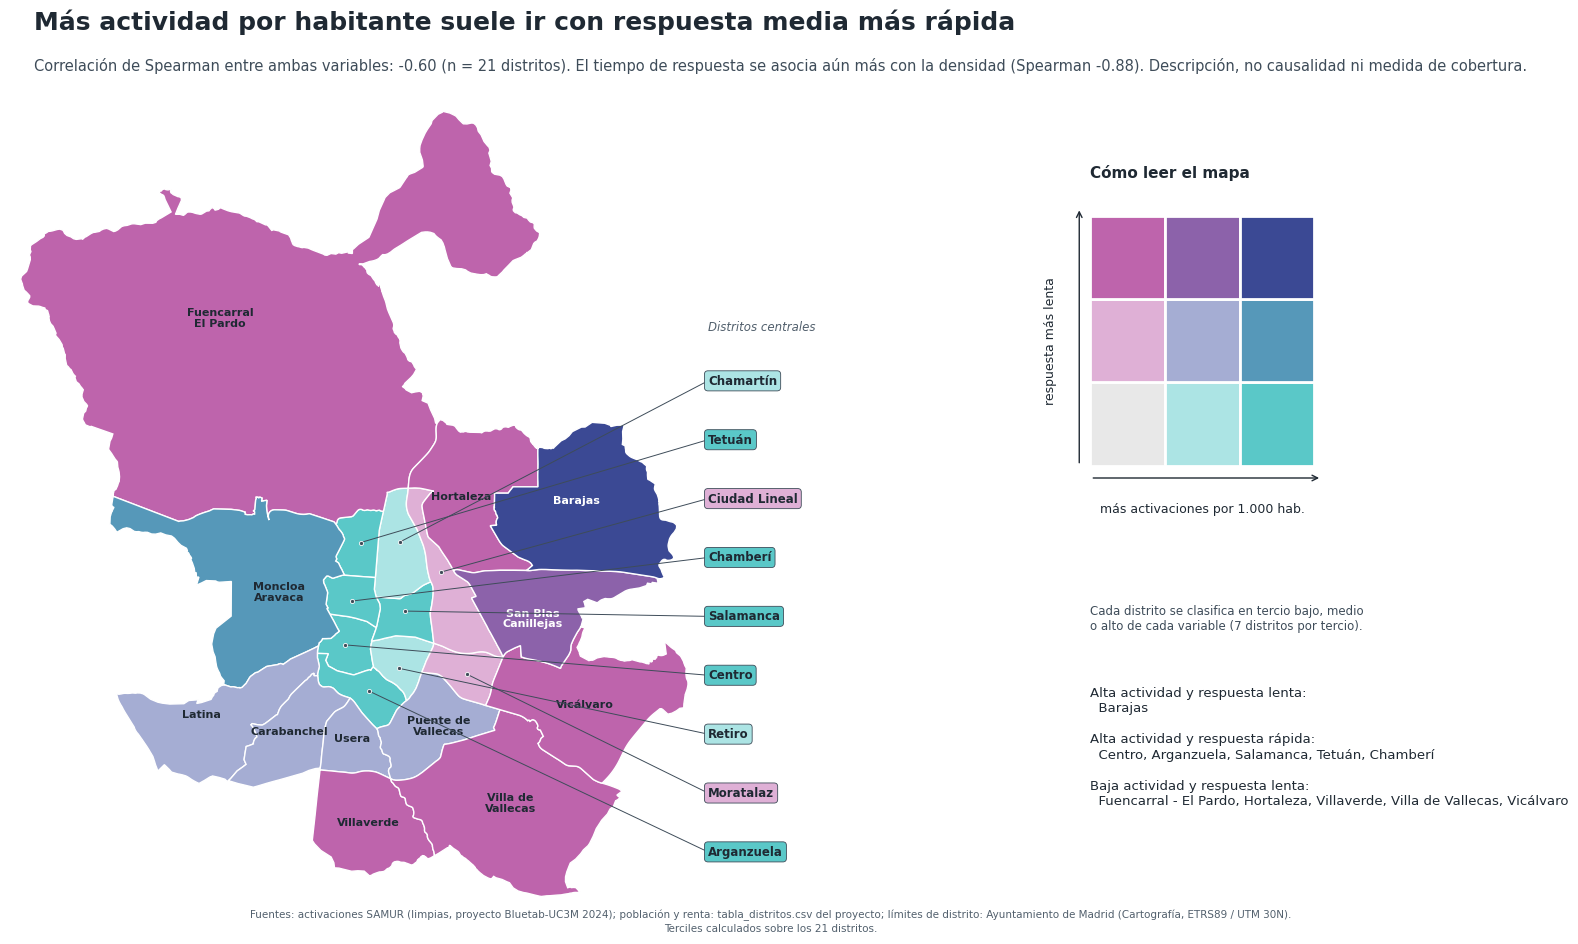

In [17]:
q=lambda s:pd.qcut(s,3,labels=False)
t["qa"]=q(t.activaciones_por_1000hab);t["qt"]=q(t.tiempo_respuesta_medio_min)
# bivariate palette (3x3), x=demand (cols), y=response time (rows)
pal=[["#e8e8e8","#ace4e4","#5ac8c8"],["#dfb0d6","#a5add3","#5698b9"],["#be64ac","#8c62aa","#3b4994"]]
colb={r.cod:pal[int(r.qt)][int(r.qa)] for _,r in t.iterrows()}
tcb={c:("white" if lum(colb[c])<.5 else INK) for c in colb}
labb={r.cod:r.lab for _,r in t.iterrows()}
fig=plt.figure(figsize=(16,9.6),facecolor=BG)
ax=fig.add_axes([.0,.04,.64,.84]);draw(ax,colb,labb,8,tcb,8.5)
# legend
lx=fig.add_axes([.70,.50,.14,.26]);lx.set_xlim(0,3);lx.set_ylim(0,3);lx.axis("off")
for i in range(3):
    for j in range(3): lx.add_patch(plt.Rectangle((j,i),1,1,fc=pal[i][j],ec="white",lw=2))
lx.annotate("",xy=(3.1,-.15),xytext=(0,-.15),arrowprops=dict(arrowstyle="->",color=INK),annotation_clip=False)
lx.annotate("",xy=(-.15,3.1),xytext=(-.15,0),arrowprops=dict(arrowstyle="->",color=INK),annotation_clip=False)
lx.text(1.5,-.45,"más activaciones por 1.000 hab.",ha="center",va="top",fontsize=9,color=INK)
lx.text(-.45,1.5,"respuesta más lenta",ha="right",va="center",rotation=90,fontsize=9,color=INK)
fig.text(.70,.80,"Cómo leer el mapa",fontsize=11,fontweight="bold",color=INK)
fig.text(.70,.355,"Cada distrito se clasifica en tercio bajo, medio\no alto de cada variable (7 distritos por tercio).",fontsize=8.5,color="#3e4c59",va="top")
hh=t[(t.qa==2)&(t.qt==2)].nombre.tolist();hl=t[(t.qa==2)&(t.qt==0)].nombre.tolist();lh=t[(t.qa==0)&(t.qt==2)].nombre.tolist()
txt=("Alta actividad y respuesta lenta:\n  "+(", ".join(hh) or "ninguno")+"\n\nAlta actividad y respuesta rápida:\n  "+(", ".join(hl) or "ninguno")+"\n\nBaja actividad y respuesta lenta:\n  "+(", ".join(lh) or "ninguno"))
fig.text(.70,.27,txt,fontsize=9.5,color=INK,va="top",linespacing=1.25)
rho=t[["activaciones_por_1000hab","tiempo_respuesta_medio_min"]].corr(method="spearman").iloc[0,1]
fig.text(.04,.975,"Más actividad por habitante suele ir con respuesta media más rápida",fontsize=18,fontweight="bold",color=INK,va="top")
rd=t[["densidad_hab_km2","tiempo_respuesta_medio_min"]].corr(method="spearman").iloc[0,1]
fig.text(.04,.925,f"Correlación de Spearman entre ambas variables: {rho:+.2f} (n = 21 distritos). El tiempo de respuesta se asocia aún más con la densidad (Spearman {rd:+.2f}). Descripción, no causalidad ni medida de cobertura.",fontsize=10.5,color="#3e4c59",va="top")
foot(fig,"Terciles calculados sobre los 21 distritos.")
fig.savefig("graficos_eda/mapa_bivariante_demanda_respuesta.png",dpi=130,facecolor=BG);plt.show()

### 10.5 Mapa 3: contexto social

**Pregunta:** ¿cómo son socialmente los distritos que acabamos de ver?

**Cómo está hecho:** tres mapas con la renta media del hogar, el índice de vulnerabilidad (0 a 1) y el porcentaje de población mayor de 65 años. Los **6 valores marcados con \*** están imputados: en los datos originales faltaban 10 huecos y se rellenaron con la media de los 3 distritos más parecidos (como indica el README del proyecto); solo 6 de ellos se ven en estos mapas.

**Cómo leerlo:** cada mapa tiene su propia escala y su rango real en la leyenda (por ejemplo, mayores de 65: de 11,2 % a 26,8 %).

**Qué vemos:** el sur (Villaverde, Usera, Vallecas, Latina) reúne menos renta y más vulnerabilidad; Salamanca, Chamartín, Retiro y Chamberí combinan más renta y más población mayor.

**Qué no dice:** no explica las activaciones. En la sección 7 ya vimos que en estos 21 distritos no aparece la relación "más vulnerabilidad, más emergencias", y estos mapas no la contradicen ni la demuestran. Los valores imputados con * conviene confirmarlos con Bluetab.

**Para qué sirve en el proyecto:** es el marco de las variables sociales del clustering y permite imaginar qué perfiles de distrito vamos a comparar.

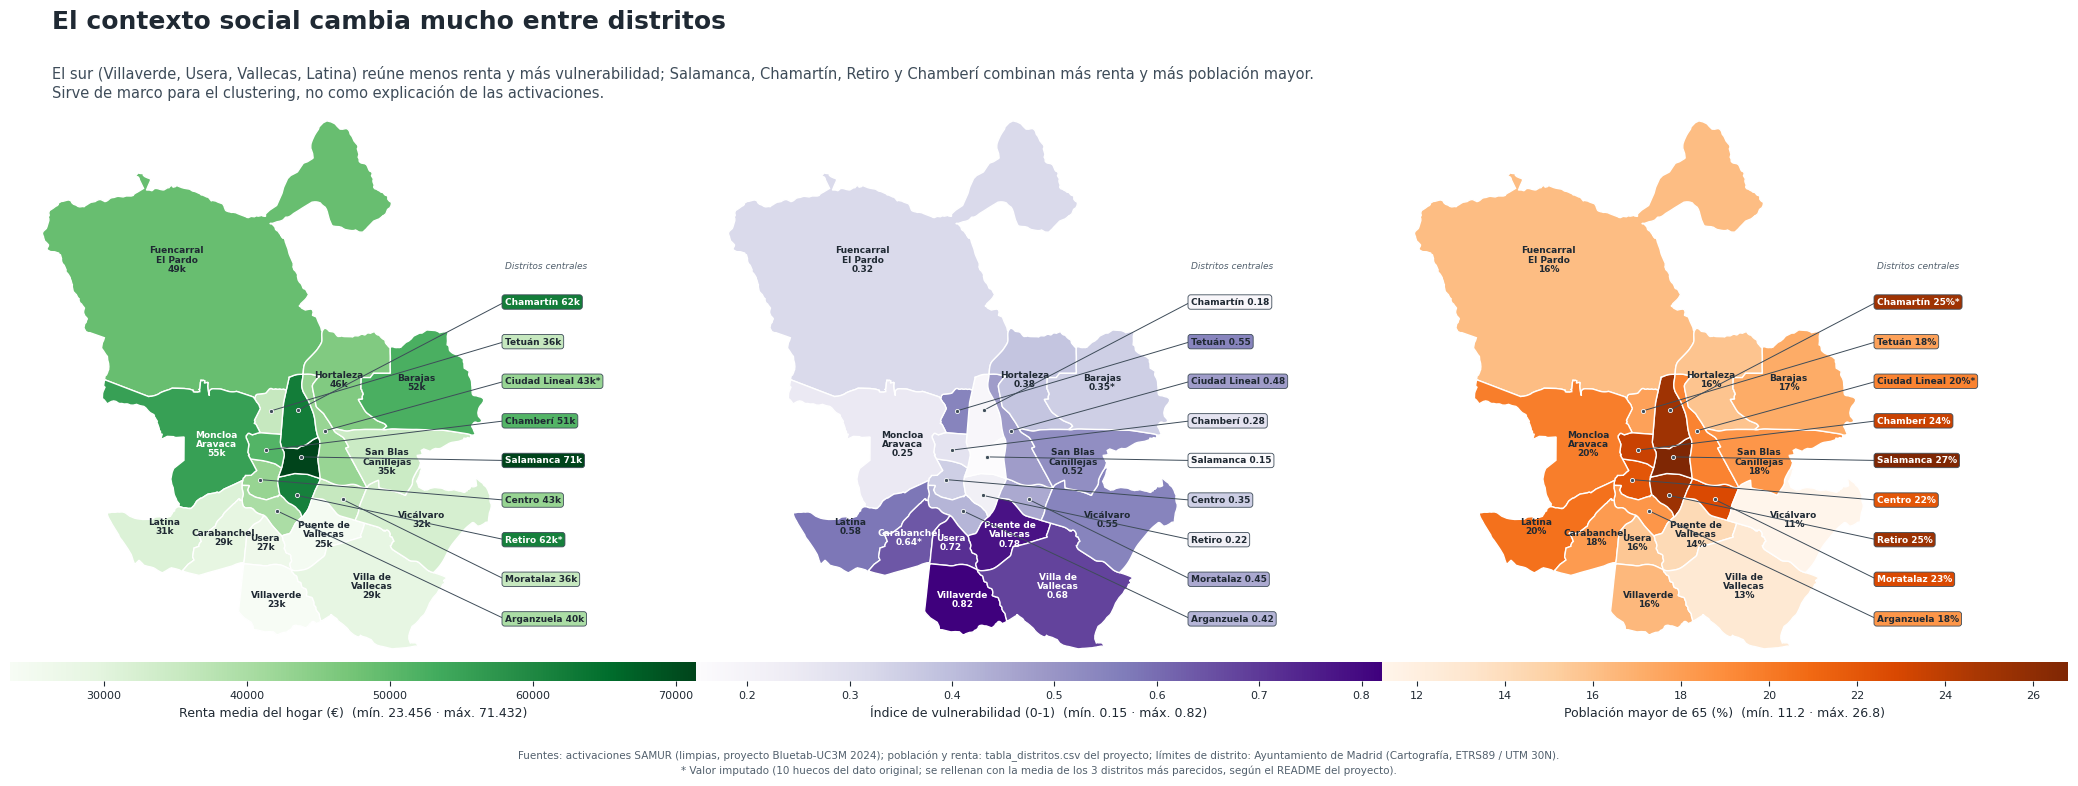

In [18]:
vars_=[("renta_media_hogar",plt.cm.Greens,lambda v:f"{v/1000:.0f}k","Renta media del hogar (€)"),
       ("indice_vulnerabilidad",plt.cm.Purples,lambda v:f"{v:.2f}","Índice de vulnerabilidad (0-1)"),
       ("pct_mayores_65",plt.cm.Oranges,lambda v:f"{v:.0f}%","Población mayor de 65 (%)")]
fig,axs=plt.subplots(1,3,figsize=(21,8),facecolor=BG)
for ax,(v,cmap,f,l) in zip(axs,vars_):
    n,col,lab,tc=choro(v,cmap,f);draw(ax,col,lab,6.5,tc,6.5);cbar(fig,ax,n,cmap,l)
fig.suptitle("El contexto social cambia mucho entre distritos",fontsize=18,fontweight="bold",color=INK,x=.03,ha="left",y=.97)
fig.text(.03,.90,"El sur (Villaverde, Usera, Vallecas, Latina) reúne menos renta y más vulnerabilidad; Salamanca, Chamartín, Retiro y Chamberí combinan más renta y más población mayor.\nSirve de marco para el clustering, no como explicación de las activaciones.",fontsize=10.5,color="#3e4c59",va="top")
foot(fig,"* Valor imputado (10 huecos del dato original; se rellenan con la media de los 3 distritos más parecidos, según el README del proyecto).")
fig.subplots_adjust(left=.01,right=.99,top=.84,bottom=.13,wspace=.0)
fig.savefig("graficos_eda/mapa_contexto_social.png",dpi=120,facecolor=BG);plt.show()

## 11. Resumen para los slides

| # | Insight | Cifra clave | Gráfico |
|---|---------|-------------|---------|
| 1 | El SAMUR no para: volumen diario enorme | 146.567 activaciones en 2024; 400 al día de media (146.567 / 366 días, promedio calculado, no una serie diaria observada) | `activaciones_por_mes.png` |
| 2 | La demanda cambia con el mes | por día: junio 438, agosto 338 (-23% respecto a junio) | `activaciones_por_mes.png` |
| 3 | El día tiene un ritmo parecido todos los meses | pico a las 13h, 3,3x el valle de las 4h | `activaciones_por_hora.png`, `heatmap_mes_hora.png` |
| 4 | La noche es otra emergencia | a las 3h, el 31% de las activaciones es por intoxicación etílica (a mediodía no llega al 3%); de 0 a 7h es el tipo nº1 | `intoxicacion_nocturna.png` |
| 5 | Qué se atiende | cardiovascular y caídas = más de 1/3 del servicio; 40% de tipos de prioridad alta (catálogo) | `tipos_emergencia_top10.png`, `prioridades.png` |
| 6 | La edad y el sexo publicados tienen un patrón a validar | reparto casi uniforme 0-99 y 50/50: no es un patrón real; pregunta para Bluetab | `edad_pacientes.png` |
| 7 | Centro es otro mundo | 141 act./1.000 residentes, 3,1x la media de distritos (2,2x el segundo); 24% de su demanda es de madrugada | `demanda_por_distrito.png` |
| 8 | En estos 21 distritos no se ve "más vulnerabilidad, más emergencias" | corr. renta-activaciones/residente +0,19 (+0,41 sin Centro); suben con el % de mayores del censo | `renta_vs_demanda.png` |
| 9 | Los distritos densos tienen respuesta más rápida | corr. -0,87 entre medias distritales (n=21); de 6,5 min (Chamberí) a 10,7 min (Barajas) | `densidad_vs_tiempo_respuesta.png` |
| 10 | Base de la unidad y distrito de la activación casi nunca coinciden | 5,8% de las identificadas (13% en los 7 distritos con base propia) | `oferta_vs_demanda.png` |
| 11 | Trauma y patología médica son 2 de cada 3 activaciones | 40,9% + 30,3% (categoría del catálogo canónico; el 100% de las activaciones ya trae tipo catalogado de la limpieza) | `activaciones_por_categoria.png` |
| 12 | Mapa: mucha actividad en el centro, respuestas más lentas en la periferia | Centro 141 act./1.000 residentes (3,5x la media simple de los otros 20 distritos, 41); Barajas 10,7 min, Villa de Vallecas 10,0, Vicálvaro 9,8 frente a 6,5 en Chamberí | `mapa_demanda_vs_respuesta.png` |
| 13 | Mapa bivariante: más actividad por habitante suele ir con respuesta más rápida | Spearman -0,60 (actividad vs tiempo) y -0,88 (densidad vs tiempo), n = 21; solo Barajas combina actividad alta y respuesta lenta. Terciles descriptivos, no clustering | `mapa_bivariante_demanda_respuesta.png` |
| 14 | Mapa social: el sur tiene menos renta y más vulnerabilidad | Villaverde, Usera, Vallecas y Latina frente a Salamanca, Chamartín, Retiro y Chamberí (más renta, más mayores). Marco del clustering, no explicación; 6 valores imputados marcados con * | `mapa_contexto_social.png` |

Conexión con el caso 1.3: los insights 7-9 y los tres mapas (12-14) son exactamente lo que el clustering tiene que capturar: distritos con perfiles de demanda y respuesta muy distintos, que piden estrategias distintas.

## 12. Limitaciones (para no vender de más)

- **Correlación ≠ causalidad**, y con 21 distritos cualquier correlación es frágil. Los insights 8 y 9 son hipótesis buenas para el clustering, no conclusiones cerradas.
- **Sin día de la semana:** el dato abierto solo trae año, mes y hora (confirmado por Bluetab). No podemos separar fin de semana de laborable ni cruzar con meteo o calendario.
- **La oferta es de catálogo y puede estar incompleta:** contar hospitales o bases no mide la cobertura real, y un distrito sin registros se contó como 0.
- **Datos imputados:** 10 huecos del socioeconómico se imputaron con los 3 distritos más parecidos (kNN) y están marcados como imputados en la tabla.
- **Edad y sexo del paciente:** el reparto es prácticamente uniforme (0-99, 50/50), algo que no se da en datos reales de emergencias. No sabemos la causa (anonimización, publicación o registro): patrón a validar con Bluetab; mientras tanto no los usamos para insights.
- **Lugar de activación ≠ residencia:** la demanda por 1.000 habitantes usa población residente, pero la gente se mueve; en Centro (ocio, turismo) el ratio mezcla demanda de visitantes con población vecina.
- **Prioridad y tipos son del catálogo:** desde la última limpieza, `tipo_emergencia` es el código del catálogo (39 tipos) y `prioridad` la gravedad típica que el catálogo asigna al tipo; la prioridad registrada en cada evento ya no está en el CSV (solo coincidía con la del catálogo en el 37,7% de las filas). Las filas cuyo tipo no describía una urgencia (5.513, el 3,6%) se eliminaron en la limpieza y no entran en estos gráficos. El script que genera el catálogo (`limpieza_tipos_emergencia.py`) cita un "anexo" como fuente de sus valores corregidos y ese documento no está en el repo; además el script sigue generando el catálogo antiguo de 42 tipos, no el de 39 que usa la limpieza (pendiente de actualizar).
- **Catálogo de unidades sin zona de cobertura:** los `unidad_id` encajan al 100% con el catálogo, pero el catálogo no dice qué zona cubre cada unidad (base ≠ zona de cobertura).
- **Distritos sin asignar:** 601 activaciones (0,4%) sin distrito de Madrid ciudad (NO CONSTA, fuera de término y carreteras; incluidas las 39 de `VALLECAS` a secas) quedan fuera del análisis por distrito.
- **Años:** las activaciones son de 2024 y el socioeconómico usa población de 2024; otros indicadores pueden ser de otra ola.
- **Mapas (sección 10):** son descriptivos. Los terciles del mapa bivariante dependen del corte y no son clustering. El denominador es población residente, no población presente (en Centro y Barajas no está medida). El tiempo de respuesta medio no es cobertura ni calidad del servicio. No hay ubicación exacta de las emergencias, por eso no hay puntos en los mapas. En el mapa social, 6 valores visibles son imputados (marcados con *).
- **Dos denominadores para Centro:** 3,1 veces la media simple de los 21 distritos (sección 7) y 3,5 veces la media simple de los otros 20 (mapa 1): mismo dato, distinto denominador, y en cada sitio se dice cuál es.